# Mini2P dynamic biphasic correction, destriping, and Suite2p registration

This notebook performs four operations in order:

1. Estimates one odd/even-line horizontal scan-phase offset per short time chunk and applies it to every frame in that chunk. A configurable wide search is used because Suite2p's built-in estimator only searches about ±10 pixels.
2. Optionally repeats the phase correction, then optionally removes the line-synchronous stripe waveform by detrending even and odd scan lines separately while preserving each frame's mean fluorescence.
3. Uses a cluster-generated, full-recording distortion-corrected TIFF.
4. Runs Suite2p motion registration on that undistorted TIFF, with Suite2p's global bidiphase correction disabled.

For two-channel interleaved data, `PHASE_ALIGNMENT_SOURCE` independently selects the channel used to estimate scan phase, while `MOTION_ALIGNMENT_SOURCE` selects the channel used by Suite2p registration. Phase and motion shifts are still applied identically to both channels so they remain aligned.

Set `RUN_DESTRIPING = False` in the settings cell to skip destriping while retaining bidiphase correction. This saves all outputs in a `without_destriping` subfolder; distortion correction and Suite2p registration retain their own settings. Set it to `True` for the original destriping workflow.


In [ ]:
from pathlib import Path
import os
import gc
import json

import matplotlib.pyplot as plt
import numpy as np
import tifffile
from suite2p.registration import bidiphase as s2p_bidiphase

# ---- Edit these settings ----
RUN_DESTRIPING = False  # True removes stripes; False keeps bidiphase correction only
# Batch workers supply these two environment variables. Without them, the
# values below preserve the notebook's original interactive single-run behavior.
WORKER_INPUT_TIFF = os.environ.get('MINI2P_WORKER_INPUT_TIFF')
WORKER_OUTPUT_DIR = os.environ.get('MINI2P_WORKER_OUTPUT_DIR')
IS_BATCH_WORKER = os.environ.get('MINI2P_BATCH_WORKER') == '1'
if IS_BATCH_WORKER:
    worker_destriping = os.environ.get('MINI2P_RUN_DESTRIPING')
    if worker_destriping not in {'0', '1'}:
        raise ValueError('Batch workers require MINI2P_RUN_DESTRIPING=0 or 1')
    RUN_DESTRIPING = worker_destriping == '1'
if bool(WORKER_INPUT_TIFF) != bool(WORKER_OUTPUT_DIR):
    raise RuntimeError(
        'MINI2P_WORKER_INPUT_TIFF and MINI2P_WORKER_OUTPUT_DIR must be set together')

if WORKER_INPUT_TIFF:
    INPUT_TIFF = Path(WORKER_INPUT_TIFF).resolve()
    INPUT_DIR = INPUT_TIFF.parent
    INPUT_FILENAME = INPUT_TIFF.name
    OUTPUT_DIR = Path(WORKER_OUTPUT_DIR).resolve()
    OUTPUT_BASE_DIR = OUTPUT_DIR.parent
    RUN_NAME = (OUTPUT_DIR.parent.name if OUTPUT_DIR.name == 'without_destriping'
                else OUTPUT_DIR.name)
else:
    INPUT_DIR = Path(
        '/Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/'
    )
    INPUT_FILENAME = '71rtask_00040.tif'
    OUTPUT_BASE_DIR = Path(
        '/Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/'
    )
    RUN_NAME = 'run-02'
    OUTPUT_DIR = OUTPUT_BASE_DIR / RUN_NAME
    INPUT_TIFF = INPUT_DIR / INPUT_FILENAME
# Keep TIFFs and Suite2p outputs separate for the no-destriping comparison.
# The batch controller passes the final output directory, including its variant.
if not RUN_DESTRIPING and not IS_BATCH_WORKER:
    OUTPUT_DIR = OUTPUT_DIR / 'without_destriping'
CORRECTION_SUFFIX = 'dynamic_bidiphase' + ('_destriped' if RUN_DESTRIPING else '')
CORRECTED_TIFF = OUTPUT_DIR / f'{INPUT_TIFF.stem}_{CORRECTION_SUFFIX}.tif'

N_CHANNELS = 2                 # pages must be ch1 red, ch2 green, interleaved
STRUCTURAL_CHANNEL = 1         # red; Suite2p uses 1-based numbering
FUNCTIONAL_CHANNEL = 2         # green; retained as the calcium/ROI channel
CHANNEL_NAMES = {STRUCTURAL_CHANNEL: 'Channel 1 — red / structural',
                 FUNCTIONAL_CHANNEL: 'Channel 2 — green / functional'}
PHASE_ALIGNMENT_SOURCE = 'functional'  # 'best_score', 'structural', or 'functional'
PHASE_SCORE_SWITCH_MARGIN = 0.0  # functional wins when its score exceeds red by this
MOTION_ALIGNMENT_SOURCE = 'functional'  # channel used by Suite2p registration

channel_by_role = {
    'functional': FUNCTIONAL_CHANNEL,
    'structural': STRUCTURAL_CHANNEL,
}
for setting_name, source in {
        'PHASE_ALIGNMENT_SOURCE': PHASE_ALIGNMENT_SOURCE,
        'MOTION_ALIGNMENT_SOURCE': MOTION_ALIGNMENT_SOURCE}.items():
    allowed = set(channel_by_role) | ({'best_score'} if setting_name == 'PHASE_ALIGNMENT_SOURCE' else set())
    if source not in allowed:
        raise ValueError(f"{setting_name} must be one of {sorted(allowed)}")
PHASE_ALIGNMENT_CHANNEL = (
    channel_by_role.get(PHASE_ALIGNMENT_SOURCE)  # None means choose per chunk
)
REGISTRATION_CHANNEL = channel_by_role[MOTION_ALIGNMENT_SOURCE]
# Used only as a display fallback; processing uses select_bidiphase_alignment().
PHASE_REFERENCE_CHANNEL = (PHASE_ALIGNMENT_CHANNEL or STRUCTURAL_CHANNEL) - 1
PHASE_CHUNK_FRAMES = 100         # 10-25 is useful when severe phase changes quickly
PHASE_ESTIMATOR = 'wide'        # 'wide' (recommended) or 'suite2p' (fixed ~±10 px)
PHASE_MAX_SHIFT_PX = 40         # raise only if the phase trace still reaches this boundary
PHASE_SCORE_CROP_PX = None      # None automatically crops PHASE_MAX_SHIFT_PX at both edges
PHASE_BOUNDARY_WARNING_PX = 2   # warn within this many pixels of the search limit
MANUAL_FIRST_PHASE_BY_START = {}   # e.g. {200: -17}; keys are chunk start timepoints
MANUAL_SECOND_PHASE_BY_START = {}  # optional residual overrides for chunked pass 2
RUN_SECOND_BIDIPHASE_PASS = True
SECOND_PASS_MODE = 'chunked'     # 'chunked' or 'whole'
SECOND_PASS_GLOBAL_MAX_FRAMES = None  # None uses every frame (may use lots of RAM)
PRESERVE_FRAME_MEAN = True
OUTPUT_DTYPE = np.float32
MAX_TIMEPOINTS = None          # set a small number for a test run
QC_START_TIMEPOINT = 0         # change this to inspect a later phase chunk
QC_REGISTRATION_FRAMES = 500   # corrected frames averaged before registration

# Distortion correction before Suite2p registration
DISTORTION_MODE = 'local_batched'  # 'local_batched', 'cluster_full', or 'off'
DISTORTION_BATCH_FRAMES = 500      # temporal memory batch; transform stays fixed
DISTORTION_TRANSFORM_MAT = Path('/Volumes/behrens/meg/transform_matrix312_A049.mat')
DISTORTION_Z_UM = 0
DISTORTION_INTERPOLATION_ORDER = 1
CROP_DISTORTION_BLACK_BORDERS = True
DISTORTION_CROP_PADDING_PX = 1
DISTORTION_CORRECTED_TIFF = OUTPUT_DIR / f'{INPUT_TIFF.stem}_{CORRECTION_SUFFIX}_undistorted.tif'
QC_DISTORTION_FRAMES = 100

# Acquisition / Suite2p settings
FS_HZ = 7.52                   # frames/s for the functional channel
DIAMETER_PX = 12
DO_NONRIGID = True
NORMALIZE_REGISTRATION_FRAMES = False
NIMG_INIT = 1000               # frames sampled to build the reference image
BAD_FRAME_THRESHOLD = 0.7      # lower excludes more questionable frames
TWO_STEP_REGISTRATION = True
REGISTRATION_BATCH_SIZE = 500  # lower this if GPU/CPU memory is limited
KEEP_RAW_BINARY = False        # avoids a second full copy of both channel binaries
SUITE2P_SAVE_FOLDER = 'suite2p'  # canonical folder for binaries, metadata, and outputs
RUN_ROI_DETECTION = False      # False = registration only

if not INPUT_TIFF.is_file():
    raise FileNotFoundError(f'Input TIFF not found: {INPUT_TIFF}')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # creates missing derivative folders
print('Input:', INPUT_TIFF)
print('Corrected TIFF:', CORRECTED_TIFF)
print('Destriping enabled:', RUN_DESTRIPING)
print(f'Biphase source policy: {PHASE_ALIGNMENT_SOURCE}')
if PHASE_ALIGNMENT_SOURCE == 'best_score':
    print('Each phase chunk compares normalized red and green scores')
else:
    print(f'Fixed biphase channel: {PHASE_ALIGNMENT_CHANNEL}')
print(f'Motion-registration source: {MOTION_ALIGNMENT_SOURCE}, channel {REGISTRATION_CHANNEL}')
print(f'Functional output remains channel {FUNCTIONAL_CHANNEL} (green)')


## Correction functions

`PHASE_ESTIMATOR='wide'` evaluates every integer shift from `-PHASE_MAX_SHIFT_PX` through `+PHASE_MAX_SHIFT_PX`. For each candidate it uses Suite2p's own `bidiphase.shift`, then measures the normalized agreement between adjacent even and odd scan lines. This removes Suite2p's built-in ±10-pixel estimation limit while preserving Suite2p's shift convention.

The score and a boundary flag are saved for every chunk. A boundary flag means the correct value may lie outside the configured search range; increase `PHASE_MAX_SHIFT_PX` and rerun the preview. `PHASE_ESTIMATOR='suite2p'` remains available for comparison.

With `PHASE_ALIGNMENT_SOURCE='best_score'`, every chunk is estimated independently from red and green. Their normalized peak scores are compared, and the winning offset is applied to both channels.


In [2]:
def apply_bidiphase(chunk, phase_px):
    # Suite2p modifies its input in place, so protect the raw chunk.
    corrected = chunk.astype(np.float32, copy=True)
    return s2p_bidiphase.shift(corrected, int(phase_px))


def _adjacent_line_score(shifted_mean, crop_px):
    """Normalized agreement between neighboring even/odd rows after a candidate shift."""
    even = shifted_mean[::2]
    odd = shifted_mean[1::2]
    n_pairs = min(len(even), len(odd))
    even, odd = even[:n_pairs], odd[:n_pairs]
    if crop_px:
        if 2 * crop_px >= even.shape[1] - 2:
            raise ValueError('PHASE_SCORE_CROP_PX is too large for the image width')
        even, odd = even[:, crop_px:-crop_px], odd[:, crop_px:-crop_px]
    # Remove each row's baseline so line brightness/stripe offsets do not drive the score.
    even = even - np.mean(even, axis=1, keepdims=True)
    odd = odd - np.mean(odd, axis=1, keepdims=True)
    numerator = float(np.sum(even * odd))
    denominator = float(np.sqrt(np.sum(even ** 2) * np.sum(odd ** 2)))
    return numerator / denominator if denominator > 0 else -np.inf


def estimate_bidiphase_diagnostics(chunk):
    """Return the phase estimate plus candidate scores and boundary diagnostics."""
    chunk = np.asarray(chunk)
    if chunk.ndim != 3 or chunk.shape[1] < 2:
        raise ValueError('Expected frames x height x width with at least two rows')
    if PHASE_ESTIMATOR == 'suite2p':
        phase = int(s2p_bidiphase.compute(chunk))
        mean_frame = np.mean(chunk.astype(np.float32), axis=0)
        crop_px = 10 if PHASE_SCORE_CROP_PX is None else int(PHASE_SCORE_CROP_PX)
        peak_score = _adjacent_line_score(
            apply_bidiphase(mean_frame[None], phase)[0], crop_px)
        return {'phase_px': phase, 'peak_score': float(peak_score),
                'score_margin': np.nan, 'at_boundary': abs(phase) >= 10,
                'candidates': None, 'scores': None}
    if PHASE_ESTIMATOR != 'wide':
        raise ValueError("PHASE_ESTIMATOR must be 'wide' or 'suite2p'")
    max_shift = int(PHASE_MAX_SHIFT_PX)
    if max_shift < 1:
        raise ValueError('PHASE_MAX_SHIFT_PX must be at least 1')
    crop_px = max_shift if PHASE_SCORE_CROP_PX is None else int(PHASE_SCORE_CROP_PX)
    mean_frame = np.mean(chunk.astype(np.float32), axis=0)
    candidates = np.arange(-max_shift, max_shift + 1, dtype=int)
    scores = np.array([
        _adjacent_line_score(apply_bidiphase(mean_frame[None], phase)[0], crop_px)
        for phase in candidates
    ])
    best_index = int(np.nanargmax(scores))
    phase = int(candidates[best_index])
    finite_scores = np.sort(scores[np.isfinite(scores)])
    margin = float(finite_scores[-1] - finite_scores[-2]) if len(finite_scores) > 1 else np.nan
    boundary_distance = max_shift - abs(phase)
    return {
        'phase_px': phase, 'peak_score': float(scores[best_index]),
        'score_margin': margin,
        'at_boundary': boundary_distance <= int(PHASE_BOUNDARY_WARNING_PX),
        'candidates': candidates, 'scores': scores,
    }


def estimate_bidiphase(chunk):
    return int(estimate_bidiphase_diagnostics(chunk)['phase_px'])


def detrend_chunk(chunk, preserve_frame_mean=True):
    """Remove separate even/odd line waveforms (existing method)."""
    chunk = chunk.astype(np.float32, copy=False)
    avg_even = np.mean(chunk[:, ::2, :], axis=1, keepdims=True)
    avg_odd = np.mean(chunk[:, 1::2, :], axis=1, keepdims=True)
    if preserve_frame_mean:
        avg_even -= np.mean(avg_even, axis=2, keepdims=True)
        avg_odd -= np.mean(avg_odd, axis=2, keepdims=True)
    output = np.empty_like(chunk, dtype=np.float32)
    output[:, ::2, :] = chunk[:, ::2, :] - avg_even
    output[:, 1::2, :] = chunk[:, 1::2, :] - avg_odd
    return output


def read_channel_chunk(tif, start, end, channel, n_channels):
    pages = channel + n_channels * np.arange(start, end)
    return np.stack([tif.pages[int(page)].asarray() for page in pages], axis=0)



def select_bidiphase_alignment(chunks):
    """Choose the phase-estimation channel for one chunk and return diagnostics."""
    if len(chunks) != N_CHANNELS:
        raise ValueError(f'Expected {N_CHANNELS} channel chunks, received {len(chunks)}')
    sources_to_score = (
        ['structural', 'functional']
        if PHASE_ALIGNMENT_SOURCE == 'best_score'
        else [PHASE_ALIGNMENT_SOURCE]
    )
    diagnostics = {
        role: estimate_bidiphase_diagnostics(chunks[channel_by_role[role] - 1])
        for role in sources_to_score
    }
    if PHASE_ALIGNMENT_SOURCE == 'best_score':
        red_score = diagnostics['structural']['peak_score']
        green_score = diagnostics['functional']['peak_score']
        selected_source = (
            'functional'
            if green_score > red_score + float(PHASE_SCORE_SWITCH_MARGIN)
            else 'structural'
        )
    else:
        selected_source = PHASE_ALIGNMENT_SOURCE
    selected = dict(diagnostics[selected_source])
    selected.update({
        'selected_source': selected_source,
        'selected_channel_one_based': channel_by_role[selected_source],
        'selected_channel_zero_based': channel_by_role[selected_source] - 1,
        'score_by_source': {
            role: float(diagnostic['peak_score'])
            for role, diagnostic in diagnostics.items()
        },
        'diagnostic_by_source': diagnostics,
    })
    return selected


## Preview phase estimates and search quality

Run this before writing the full TIFF. The upper plot shows the phase over time; red points mark estimates at or near the configured search boundary. The lower plot shows the best normalized adjacent-line score. Inspect red points and unusually low scores before preprocessing.

If values reach ±`PHASE_MAX_SHIFT_PX`, increase the search range. If estimates jump within a section whose mean remains doubled, reduce `PHASE_CHUNK_FRAMES` (for example from 20 to 10). The optional score-curve plot for the worst chunk helps reveal ambiguous competing peaks.


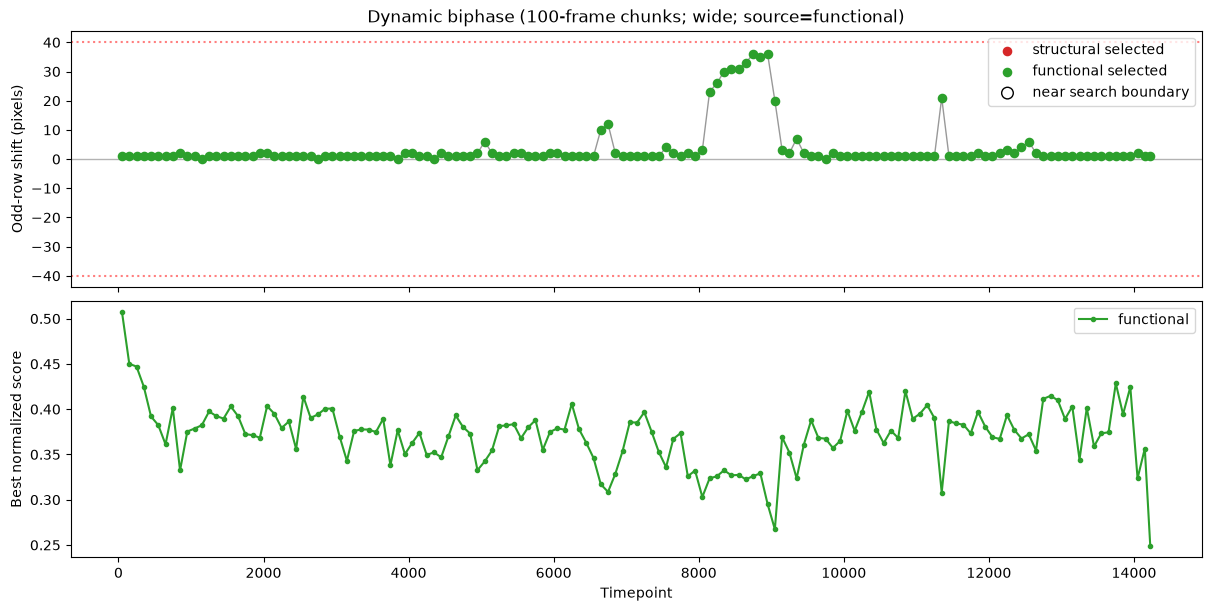

Phase range: (0, 36)
Selected source counts: {np.str_('functional'): 143}


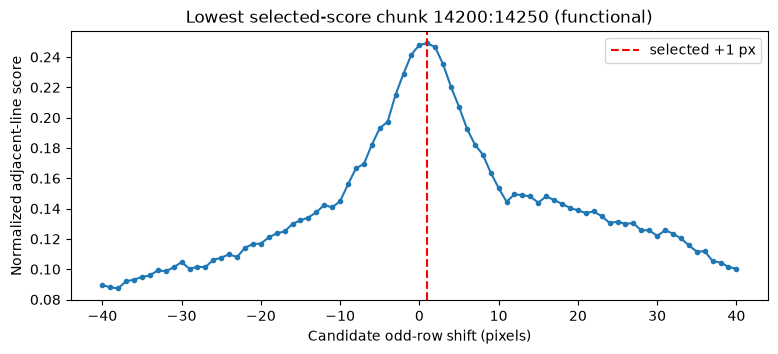

In [3]:
if IS_BATCH_WORKER:
    print('Batch worker skipped: adaptive phase-trace preview')
else:
    def inspect_phase_trace(tiff_path, n_channels, reference_channel, chunk_frames):
        records = []
        with tifffile.TiffFile(tiff_path) as tif:
            if len(tif.pages) % n_channels:
                raise ValueError('TIFF page count is not divisible by N_CHANNELS')
            n_timepoints = len(tif.pages) // n_channels
            if MAX_TIMEPOINTS is not None:
                n_timepoints = min(n_timepoints, int(MAX_TIMEPOINTS))
            for start in range(0, n_timepoints, chunk_frames):
                end = min(start + chunk_frames, n_timepoints)
                chunks = [
                    read_channel_chunk(tif, start, end, channel, n_channels)
                    for channel in range(n_channels)]
                diagnostic = select_bidiphase_alignment(chunks)
                records.append({
                    'start': start, 'end': end,
                    'phase_px': diagnostic['phase_px'],
                    'peak_score': diagnostic['peak_score'],
                    'score_margin': diagnostic['score_margin'],
                    'at_boundary': diagnostic['at_boundary'],
                    'selected_source': diagnostic['selected_source'],
                    'selected_channel_zero_based': diagnostic['selected_channel_zero_based'],
                    'score_by_source': diagnostic['score_by_source'],
                })
        return records


    phase_preview = inspect_phase_trace(
        INPUT_TIFF, N_CHANNELS, PHASE_REFERENCE_CHANNEL, PHASE_CHUNK_FRAMES)
    centers = np.array([(row['start'] + row['end'] - 1) / 2 for row in phase_preview])
    values = np.array([row['phase_px'] for row in phase_preview])
    scores = np.array([row['peak_score'] for row in phase_preview])
    boundary = np.array([row['at_boundary'] for row in phase_preview], dtype=bool)
    selected_sources = np.array([row['selected_source'] for row in phase_preview])
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)
    for role, color in [('structural', 'tab:red'), ('functional', 'tab:green')]:
        selected = selected_sources == role
        axes[0].scatter(centers[selected], values[selected], color=color, s=35,
                        label=f'{role} selected', zorder=3)
    axes[0].plot(centers, values, color='0.6', linewidth=1)
    axes[0].scatter(centers[boundary], values[boundary], facecolors='none',
                    edgecolors='black', s=70, label='near search boundary', zorder=4)
    axes[0].axhline(0, color='0.7', linewidth=1)
    if PHASE_ESTIMATOR == 'wide':
        axes[0].axhline(PHASE_MAX_SHIFT_PX, color='red', linestyle=':', alpha=0.5)
        axes[0].axhline(-PHASE_MAX_SHIFT_PX, color='red', linestyle=':', alpha=0.5)
    axes[0].set_ylabel('Odd-row shift (pixels)')
    axes[0].set_title(f'Dynamic biphase ({PHASE_CHUNK_FRAMES}-frame chunks; '
                      f'{PHASE_ESTIMATOR}; source={PHASE_ALIGNMENT_SOURCE})')
    axes[0].legend(loc='best')
    for role, color in [('structural', 'tab:red'), ('functional', 'tab:green')]:
        role_scores = np.array([
            row['score_by_source'].get(role, np.nan) for row in phase_preview])
        if np.any(np.isfinite(role_scores)):
            axes[1].plot(centers, role_scores, '.-', color=color, label=role)
    axes[1].set_xlabel('Timepoint')
    axes[1].set_ylabel('Best normalized score')
    axes[1].legend(loc='best')
    plt.show()
    print('Phase range:', (int(np.min(values)), int(np.max(values))))
    print('Selected source counts:', {
        role: int(np.sum(selected_sources == role))
        for role in np.unique(selected_sources)})
    if np.any(boundary):
        starts = [row['start'] for row in phase_preview if row['at_boundary']]
        print('WARNING: search-boundary chunks start at:', starts)
        print('Increase PHASE_MAX_SHIFT_PX and rerun this preview.')

    # Show the score curve for the selected channel in the lowest-scoring chunk.
    finite = np.isfinite(scores)
    if PHASE_ESTIMATOR == 'wide' and np.any(finite):
        worst_row = phase_preview[int(np.where(finite)[0][np.argmin(scores[finite])])]
        with tifffile.TiffFile(INPUT_TIFF) as tif:
            worst_chunks = [
                read_channel_chunk(tif, worst_row['start'], worst_row['end'],
                                   channel, N_CHANNELS)
                for channel in range(N_CHANNELS)]
        worst_selection = select_bidiphase_alignment(worst_chunks)
        worst_diagnostic = worst_selection['diagnostic_by_source'][
            worst_selection['selected_source']]
        plt.figure(figsize=(9, 3.5))
        plt.plot(worst_diagnostic['candidates'], worst_diagnostic['scores'], '.-')
        plt.axvline(worst_diagnostic['phase_px'], color='red', linestyle='--',
                    label=f"selected {worst_diagnostic['phase_px']:+d} px")
        plt.xlabel('Candidate odd-row shift (pixels)')
        plt.ylabel('Normalized adjacent-line score')
        plt.title(f"Lowest selected-score chunk {worst_row['start']}:{worst_row['end']} "
                  f"({worst_selection['selected_source']})")
        plt.legend()
        plt.show()


## Interactive manual offset for the lowest-scoring chunk

Use this after running the phase-preview cell. The slider applies the selected integer offset to both channels and compares it with the uncorrected chunk using fixed contrast. The image edges affected by the largest tested shift are hidden so zero-filled borders do not influence visual judgement.

When the image looks best, copy the displayed dictionary entry into `MANUAL_FIRST_PHASE_BY_START` in the settings cell. The automatic estimate is the slider's initial value. This is a QC/manual-override tool only; it does not modify the source TIFF.


In [4]:
if IS_BATCH_WORKER:
    print('Batch worker skipped: manual phase slider')
else:
    # If this import fails, run: %pip install ipywidgets
    import ipywidgets as widgets
    from IPython.display import display

    if PHASE_ESTIMATOR != 'wide':
        print("Set PHASE_ESTIMATOR='wide' and rerun the preview to use this slider.")
    elif 'worst_row' not in globals():
        print('Run the phase-preview cell above first.')
    else:
        manual_start = int(worst_row['start'])
        manual_end = int(worst_row['end'])
        with tifffile.TiffFile(INPUT_TIFF) as tif:
            manual_raw_chunks = [
                read_channel_chunk(tif, manual_start, manual_end, channel, N_CHANNELS)
                for channel in range(N_CHANNELS)
            ]

        manual_raw_means = [np.mean(chunk, axis=0) for chunk in manual_raw_chunks]
        manual_limits = []
        for image in manual_raw_means:
            finite = image[np.isfinite(image)]
            manual_limits.append(tuple(np.percentile(finite, [1, 99.8])))

        automatic_phase = int(worst_row['phase_px'])
        manual_phase_slider = widgets.IntSlider(
            value=automatic_phase,
            min=-int(PHASE_MAX_SHIFT_PX),
            max=int(PHASE_MAX_SHIFT_PX),
            step=1,
            description='Offset (px):',
            continuous_update=False,
            readout=True,
            layout=widgets.Layout(width='650px'),
            style={'description_width': '100px'},
        )
        manual_override_text = widgets.HTML()

        def show_manual_phase(offset_px):
            offset_px = int(offset_px)
            corrected = [apply_bidiphase(chunk, offset_px) for chunk in manual_raw_chunks]
            corrected_means = [np.mean(chunk, axis=0) for chunk in corrected]
            crop = int(PHASE_MAX_SHIFT_PX)
            x_slice = slice(crop, -crop) if 2 * crop < manual_raw_means[0].shape[1] else slice(None)

            fig, axes = plt.subplots(
                N_CHANNELS, 2, figsize=(12, 5 * N_CHANNELS),
                constrained_layout=True, squeeze=False)
            for channel_zero_based in range(N_CHANNELS):
                channel_one_based = channel_zero_based + 1
                vmin, vmax = manual_limits[channel_zero_based]
                images = [manual_raw_means[channel_zero_based],
                          corrected_means[channel_zero_based]]
                titles = ['Uncorrected', f'Manual offset {offset_px:+d} px']
                for ax, image, title in zip(axes[channel_zero_based], images, titles):
                    ax.imshow(image[:, x_slice], cmap='gray', vmin=vmin, vmax=vmax,
                              interpolation='nearest')
                    ax.set_title(f'{CHANNEL_NAMES[channel_one_based]}\n{title}')
                    ax.axis('off')
            manual_score_channel = int(worst_row.get(
                'selected_channel_zero_based', PHASE_REFERENCE_CHANNEL))
            score = _adjacent_line_score(
                corrected_means[manual_score_channel], crop)
            fig.suptitle(
                f'Worst chunk {manual_start}:{manual_end} — score {score:.4f} '
                f'(automatic estimate {automatic_phase:+d} px)', fontsize=14)
            plt.show()
            manual_override_text.value = (
                '<b>Copy into the settings cell:</b> '
                f'<code>MANUAL_FIRST_PHASE_BY_START = {{{manual_start}: {offset_px}}}</code>'
            )

        manual_phase_output = widgets.interactive_output(
            show_manual_phase, {'offset_px': manual_phase_slider})
        display(widgets.VBox([
            widgets.HTML(
                f'<b>Chunk {manual_start}:{manual_end}</b> — automatic offset '
                f'<code>{automatic_phase:+d} px</code>'),
            manual_phase_slider,
            manual_override_text,
            manual_phase_output,
        ]))


## Write the corrected TIFF

The output retains the input page order. A JSON sidecar records every chunk's phase estimate and all relevant parameters. Existing output is not overwritten unless `OVERWRITE=True`.

In [6]:
OVERWRITE = True

def estimate_whole_recording_residual_phase(tif, n_timepoints):
    """Estimate pass-2 residual after adaptive pass 1, before destriping."""
    if SECOND_PASS_GLOBAL_MAX_FRAMES is None:
        sample_indices = np.arange(n_timepoints)
    else:
        sample_count = min(int(SECOND_PASS_GLOBAL_MAX_FRAMES), n_timepoints)
        sample_indices = np.unique(
            np.linspace(0, n_timepoints - 1, sample_count, dtype=int))
    sampled_after_first = [[] for _ in range(N_CHANNELS)]
    for chunk_start in range(0, n_timepoints, PHASE_CHUNK_FRAMES):
        chunk_end = min(chunk_start + PHASE_CHUNK_FRAMES, n_timepoints)
        selected_indices = sample_indices[
            (sample_indices >= chunk_start) & (sample_indices < chunk_end)]
        if not len(selected_indices):
            continue
        chunks = [
            read_channel_chunk(tif, chunk_start, chunk_end, channel, N_CHANNELS)
            for channel in range(N_CHANNELS)]
        first_selection = select_bidiphase_alignment(chunks)
        first_phase = int(MANUAL_FIRST_PHASE_BY_START.get(
            chunk_start, first_selection['phase_px']))
        after_first = [apply_bidiphase(chunk, first_phase) for chunk in chunks]
        relative = selected_indices - chunk_start
        for channel in range(N_CHANNELS):
            sampled_after_first[channel].append(after_first[channel][relative])
        del chunks, after_first
    samples = [np.concatenate(parts, axis=0) for parts in sampled_after_first]
    selection = select_bidiphase_alignment(samples)
    residual = int(selection['phase_px'])
    print(f'Whole-recording second phase: {residual:+d} px from '
          f'{len(sample_indices)} frames; source={selection["selected_source"]}; '
          f'scores={selection["score_by_source"]}')
    del samples, sampled_after_first
    gc.collect()
    return residual, int(len(sample_indices)), selection


def preprocess_tiff(input_tiff, output_tiff):
    if output_tiff.exists() and not OVERWRITE:
        raise FileExistsError(f'{output_tiff} exists; set OVERWRITE=True to replace it')
    phase_records = []
    with tifffile.TiffFile(input_tiff) as tif:
        n_pages = len(tif.pages)
        if n_pages % N_CHANNELS:
            raise ValueError(f'{n_pages} pages is not divisible by {N_CHANNELS} channels')
        n_timepoints = n_pages // N_CHANNELS
        if MAX_TIMEPOINTS is not None:
            n_timepoints = min(n_timepoints, int(MAX_TIMEPOINTS))
        if SECOND_PASS_MODE not in {'chunked', 'whole'}:
            raise ValueError("SECOND_PASS_MODE must be 'chunked' or 'whole'")
        global_second_phase = None
        global_sample_count = None
        global_second_selection = None
        if RUN_SECOND_BIDIPHASE_PASS and SECOND_PASS_MODE == 'whole':
            global_second_phase, global_sample_count, global_second_selection = (
                estimate_whole_recording_residual_phase(tif, n_timepoints))

        with tifffile.TiffWriter(output_tiff, bigtiff=True) as writer:
            for start in range(0, n_timepoints, PHASE_CHUNK_FRAMES):
                end = min(start + PHASE_CHUNK_FRAMES, n_timepoints)
                chunks = [read_channel_chunk(tif, start, end, ch, N_CHANNELS)
                          for ch in range(N_CHANNELS)]
                first_diagnostic = select_bidiphase_alignment(chunks)
                first_phase = int(MANUAL_FIRST_PHASE_BY_START.get(
                    start, first_diagnostic['phase_px']))
                after_first = [apply_bidiphase(chunk, first_phase) for chunk in chunks]
                second_phase = 0
                second_diagnostic = None
                after_second = after_first
                if RUN_SECOND_BIDIPHASE_PASS:
                    second_diagnostic = (
                        global_second_selection if SECOND_PASS_MODE == 'whole'
                        else select_bidiphase_alignment(after_first))
                    second_phase = int(MANUAL_SECOND_PHASE_BY_START.get(
                        start, global_second_phase if SECOND_PASS_MODE == 'whole'
                        else second_diagnostic['phase_px']))
                    after_second = [
                        apply_bidiphase(chunk, second_phase) for chunk in after_first]
                corrected = ([
                    detrend_chunk(chunk, PRESERVE_FRAME_MEAN) for chunk in after_second]
                    if RUN_DESTRIPING else after_second)

                for frame_index in range(end - start):
                    for channel in range(N_CHANNELS):
                        writer.write(corrected[channel][frame_index].astype(OUTPUT_DTYPE),
                                     contiguous=False)
                phase_records.append({
                    'start': start, 'end': end,
                    'first_phase_px': int(first_phase),
                    'second_phase_px': int(second_phase),
                    'first_peak_score': float(first_diagnostic['peak_score']),
                    'first_score_margin': float(first_diagnostic['score_margin']),
                    'first_at_search_boundary': bool(first_diagnostic['at_boundary']),
                    'first_selected_source': first_diagnostic['selected_source'],
                    'first_score_by_source': first_diagnostic['score_by_source'],
                    'second_selected_source': (
                        second_diagnostic['selected_source']
                        if second_diagnostic is not None else None),
                    'second_score_by_source': (
                        second_diagnostic['score_by_source']
                        if second_diagnostic is not None else None),
                })
                print(f'{end:>7}/{n_timepoints}; first={first_phase:+d} px; '
                      f'second={second_phase:+d} px; source={first_diagnostic["selected_source"]}; '
                      f'score={first_diagnostic["peak_score"]:.3f}; '
                      f'boundary={first_diagnostic["at_boundary"]}; '
                      f'destriping={RUN_DESTRIPING}')
                del chunks, after_first, after_second, corrected
                gc.collect()

    metadata = {
        'run_name': RUN_NAME,
        'input_tiff': str(input_tiff), 'output_tiff': str(output_tiff),
        'n_channels': N_CHANNELS,
        'structural_channel_one_based': STRUCTURAL_CHANNEL,
        'functional_channel_one_based': FUNCTIONAL_CHANNEL,
        'phase_alignment_source': PHASE_ALIGNMENT_SOURCE,
        'phase_alignment_channel_one_based': PHASE_ALIGNMENT_CHANNEL,
        'phase_score_switch_margin': PHASE_SCORE_SWITCH_MARGIN,
        'motion_alignment_source': MOTION_ALIGNMENT_SOURCE,
        'registration_channel_one_based': REGISTRATION_CHANNEL,
        'phase_reference_channel_zero_based': PHASE_REFERENCE_CHANNEL,
        'phase_chunk_frames': PHASE_CHUNK_FRAMES,
        'phase_method': PHASE_ESTIMATOR,
        'phase_max_shift_px': PHASE_MAX_SHIFT_PX if PHASE_ESTIMATOR == 'wide' else 10,
        'phase_score_crop_px': PHASE_SCORE_CROP_PX,
        'phase_boundary_warning_px': PHASE_BOUNDARY_WARNING_PX,
        'manual_first_phase_by_start': MANUAL_FIRST_PHASE_BY_START,
        'manual_second_phase_by_start': MANUAL_SECOND_PHASE_BY_START,
        'second_pass_enabled': RUN_SECOND_BIDIPHASE_PASS,
        'second_pass_mode': SECOND_PASS_MODE if RUN_SECOND_BIDIPHASE_PASS else None,
        'global_second_phase_px': global_second_phase,
        'global_second_phase_sample_count': global_sample_count,
        'destriping_enabled': RUN_DESTRIPING,
        'operation_order': (['first_biphase']
                            + (['second_biphase'] if RUN_SECOND_BIDIPHASE_PASS else [])
                            + (['destriping'] if RUN_DESTRIPING else [])),
        'preserve_frame_mean': PRESERVE_FRAME_MEAN, 'chunks': phase_records,
    }
    sidecar = output_tiff.with_suffix('.phase.json')
    sidecar.write_text(json.dumps(metadata, indent=2))
    print('Saved:', output_tiff)
    print('Saved:', sidecar)
    return {
        'chunks': phase_records,
        'global_second_phase_px': global_second_phase,
        'global_second_phase_sample_count': global_sample_count,
    }


phase_processing_summary = preprocess_tiff(INPUT_TIFF, CORRECTED_TIFF)
phase_records = phase_processing_summary['chunks']
SUITE2P_INPUT_TIFF = CORRECTED_TIFF


    100/14250; first=+1 px; second=+0 px; source=functional; score=0.507; boundary=False; destriping=False
    200/14250; first=+1 px; second=+0 px; source=functional; score=0.450; boundary=False; destriping=False
    300/14250; first=+1 px; second=+0 px; source=functional; score=0.447; boundary=False; destriping=False
    400/14250; first=+1 px; second=+0 px; source=functional; score=0.425; boundary=False; destriping=False
    500/14250; first=+1 px; second=+0 px; source=functional; score=0.392; boundary=False; destriping=False
    600/14250; first=+1 px; second=+0 px; source=functional; score=0.382; boundary=False; destriping=False
    700/14250; first=+1 px; second=+0 px; source=functional; score=0.361; boundary=False; destriping=False
    800/14250; first=+1 px; second=+0 px; source=functional; score=0.401; boundary=False; destriping=False
    900/14250; first=+2 px; second=+0 px; source=functional; score=0.332; boundary=False; destriping=False
   1000/14250; first=+1 px; second=+0

## QC 1 — biphasic correction, before and after

This plots the mean of one phase-estimation chunk for both channels before and after Suite2p's biphasic shift. Each channel uses one shared percentile range across its before/after pair.

In [7]:
def plot_before_after(before_stacks, after_stacks, step_name, percentiles=(1, 99.8)):
    fig, axes = plt.subplots(N_CHANNELS, 2, figsize=(12, 5 * N_CHANNELS),
                             constrained_layout=True, squeeze=False)
    for channel_zero_based in range(N_CHANNELS):
        channel_one_based = channel_zero_based + 1
        before_mean = np.mean(before_stacks[channel_zero_based], axis=0)
        after_mean = np.mean(after_stacks[channel_zero_based], axis=0)
        finite = np.concatenate([before_mean[np.isfinite(before_mean)],
                                 after_mean[np.isfinite(after_mean)]])
        vmin, vmax = np.percentile(finite, percentiles)
        for ax, image, state in zip(axes[channel_zero_based],
                                    [before_mean, after_mean], ['Before', 'After']):
            ax.imshow(image, cmap='gray', vmin=vmin, vmax=vmax, interpolation='nearest')
            ax.set_title(f'{CHANNEL_NAMES[channel_one_based]}\n{state} {step_name}')
            ax.axis('off')
    plt.show()

QC frames 0:100; first phase=+1 px; source=functional; scores={'functional': 0.5069334841002364}; score=0.507; near boundary=False


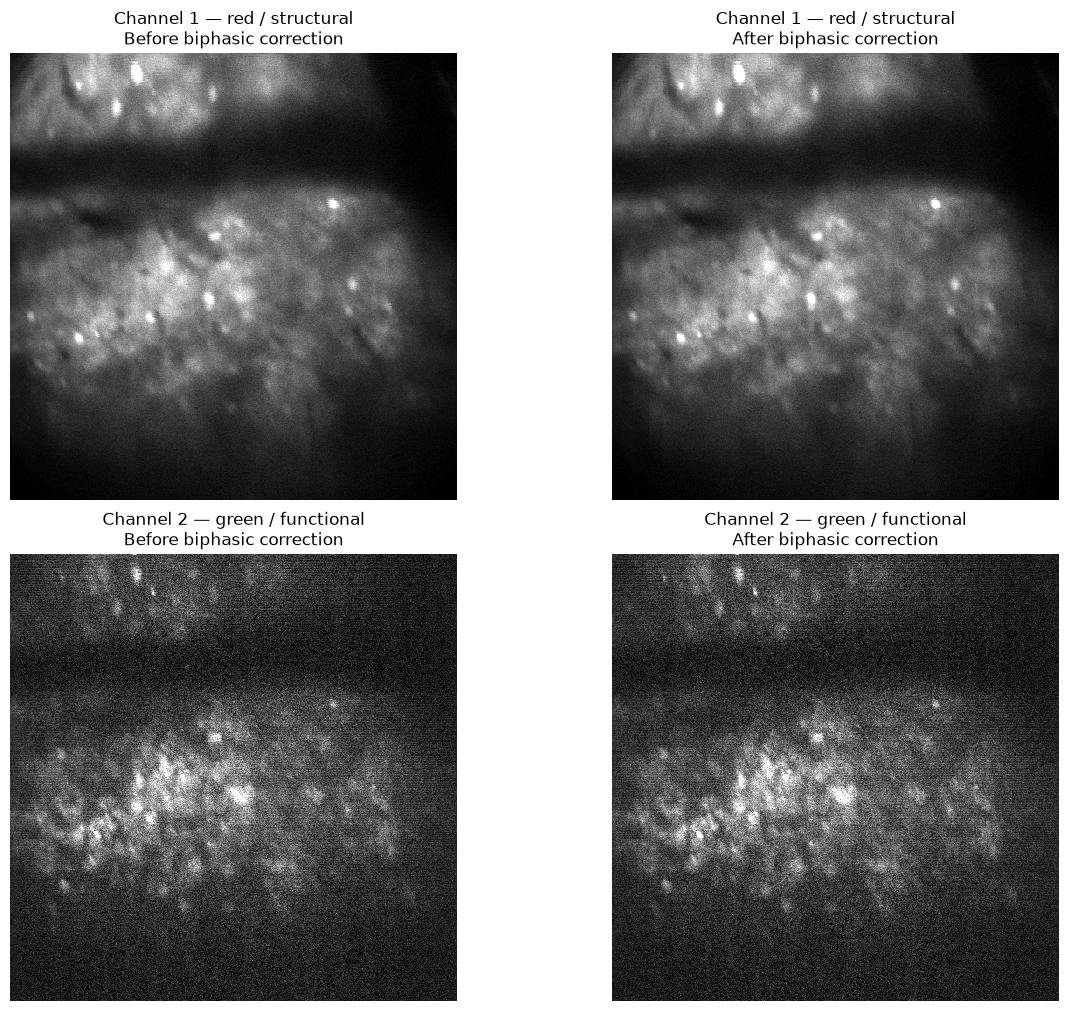

In [8]:
if IS_BATCH_WORKER:
    print('Batch worker skipped: biphase before/after QC')
else:
    with tifffile.TiffFile(INPUT_TIFF) as tif:
        n_timepoints = len(tif.pages) // N_CHANNELS
        qc_start = int(QC_START_TIMEPOINT)
        qc_end = min(qc_start + PHASE_CHUNK_FRAMES, n_timepoints)
        if not 0 <= qc_start < qc_end:
            raise ValueError('QC_START_TIMEPOINT is outside the recording')
        qc_raw_chunks = [read_channel_chunk(tif, qc_start, qc_end, channel, N_CHANNELS)
                         for channel in range(N_CHANNELS)]

    qc_first_diagnostic = select_bidiphase_alignment(qc_raw_chunks)
    qc_phase_px = int(MANUAL_FIRST_PHASE_BY_START.get(
        qc_start, qc_first_diagnostic['phase_px']))
    qc_phase_chunks = [apply_bidiphase(chunk, qc_phase_px) for chunk in qc_raw_chunks]
    qc_second_phase_px = 0
    qc_final_phase_chunks = qc_phase_chunks
    if RUN_SECOND_BIDIPHASE_PASS:
        qc_second_phase_px = (
            phase_processing_summary['global_second_phase_px']
            if SECOND_PASS_MODE == 'whole' else
            int(MANUAL_SECOND_PHASE_BY_START.get(
                qc_start, select_bidiphase_alignment(qc_phase_chunks)['phase_px']))
        )
        qc_final_phase_chunks = [
            apply_bidiphase(chunk, qc_second_phase_px) for chunk in qc_phase_chunks]
    print(f'QC frames {qc_start}:{qc_end}; first phase={qc_phase_px:+d} px; '
          f'source={qc_first_diagnostic["selected_source"]}; '
          f'scores={qc_first_diagnostic["score_by_source"]}; '
          f'score={qc_first_diagnostic["peak_score"]:.3f}; '
          f'near boundary={qc_first_diagnostic["at_boundary"]}')
    plot_before_after(qc_raw_chunks, qc_phase_chunks, 'biphasic correction')


## QC 1b — first versus second biphase, before destriping

When the optional second pass is enabled, this compares its input and output before any detrending/destriping. Both columns use the same frames and matched display limits within each channel.

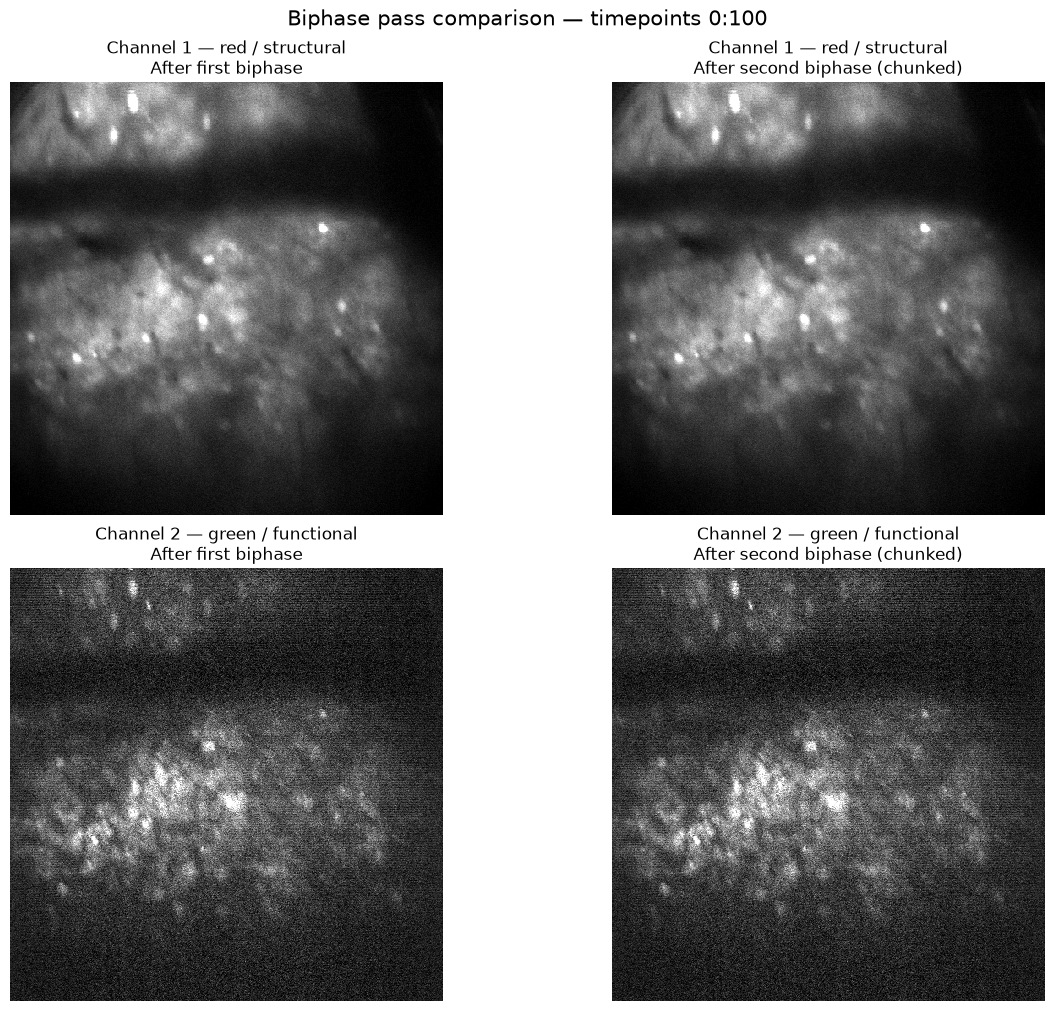

In [9]:
if IS_BATCH_WORKER:
    print('Batch worker skipped: first/second biphase QC')
else:
    def plot_first_vs_second_biphase(first_pass_stacks, second_pass_stacks, frame_range):
        fig, axes = plt.subplots(N_CHANNELS, 2, figsize=(12, 5 * N_CHANNELS),
                                 constrained_layout=True, squeeze=False)
        for channel_zero_based in range(N_CHANNELS):
            channel_one_based = channel_zero_based + 1
            first_mean = np.mean(first_pass_stacks[channel_zero_based], axis=0)
            second_mean = np.mean(second_pass_stacks[channel_zero_based], axis=0)
            finite = np.concatenate([first_mean[np.isfinite(first_mean)],
                                     second_mean[np.isfinite(second_mean)]])
            vmin, vmax = np.percentile(finite, [1, 99.8])
            titles = ['After first biphase',
                      f'After second biphase ({SECOND_PASS_MODE})']
            for ax, image, title in zip(axes[channel_zero_based],
                                        [first_mean, second_mean], titles):
                ax.imshow(image, cmap='gray', vmin=vmin, vmax=vmax,
                          interpolation='nearest')
                ax.set_title(f'{CHANNEL_NAMES[channel_one_based]}\n{title}')
                ax.axis('off')
        fig.suptitle(f'Biphase pass comparison — timepoints {frame_range[0]}:{frame_range[1]}',
                     fontsize=15)
        plt.show()

    if RUN_SECOND_BIDIPHASE_PASS:
        plot_first_vs_second_biphase(
            qc_phase_chunks, qc_final_phase_chunks, (qc_start, qc_end))
    else:
        print('Second biphasic pass disabled; no pass-1/pass-2 comparison to show')


## QC 2 — detrending/destriping, before and after

This uses the phase-corrected chunk above as the input, then shows both channels before and after the existing baseline-preserving even/odd-line detrending.

In [ ]:
if IS_BATCH_WORKER:
    print('Batch worker skipped: destriping QC')
elif not RUN_DESTRIPING:
    qc_destriped_chunks = qc_final_phase_chunks
    print('Destriping disabled; retaining the bidiphase-corrected frames')
else:
    qc_destriped_chunks = [
        detrend_chunk(chunk, preserve_frame_mean=PRESERVE_FRAME_MEAN)
        for chunk in qc_final_phase_chunks
    ]
    plot_before_after(qc_final_phase_chunks, qc_destriped_chunks, 'destriping')


## Preprocessing summary

The second pass is now integrated into the main preprocessing cell so that both phase corrections occur before destriping. `SECOND_PASS_MODE='chunked'` recalculates the residual after pass 1 for each chunk; `'whole'` estimates one residual from pass-1-corrected frames distributed across the recording. The cell below reports the selected ordering and phases; it does not write a post-destriping phase-correction TIFF.

In [10]:
second_phase_records = (phase_records if RUN_SECOND_BIDIPHASE_PASS else None)
print('Operation order: first biphase -> optional second biphase -> destriping')
print('Second pass enabled:', RUN_SECOND_BIDIPHASE_PASS)
if RUN_SECOND_BIDIPHASE_PASS:
    print('Second pass mode:', SECOND_PASS_MODE)
    print('Whole-recording second phase:',
          phase_processing_summary['global_second_phase_px'])
print('Biphase-corrected/destriped TIFF:', CORRECTED_TIFF)

Operation order: first biphase -> optional second biphase -> destriping
Second pass enabled: True
Second pass mode: chunked
Whole-recording second phase: None
Biphase-corrected/destriped TIFF: /Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/run-02/without_destriping/71rtask_00040_dynamic_bidiphase.tif


## Distortion correction before registration: local batches or cluster

`DISTORTION_MODE='local_batched'` applies one fixed calibration transform to every complete frame, processing `DISTORTION_BATCH_FRAMES` timepoints at a time to control memory. The transform and crop are calculated once for the entire recording; they are not re-estimated per batch. Therefore changing the batch size does not change the corrected pixels.

Use `'cluster_full'` when `DISTORTION_CORRECTED_TIFF` was created by the supplied SLURM worker, or `'off'` to register the biphase-corrected/destriped TIFF without distortion correction. All modes keep distortion correction before Suite2p motion registration.


In [12]:
import sys

# Reuse the tested calibration/crop functions used by the SLURM worker.
candidate_script_dirs = [Path.cwd() / 'scripts', Path.cwd()]
distortion_script_dir = next(
    (path for path in candidate_script_dirs
     if (path / 'distortion_correct_full_recording.py').is_file()), None)
if distortion_script_dir is None:
    raise FileNotFoundError(
        'Could not locate scripts/distortion_correct_full_recording.py')
if str(distortion_script_dir) not in sys.path:
    sys.path.insert(0, str(distortion_script_dir))
from distortion_correct_full_recording import load_transform, make_maps, crop_bounds
from scipy.ndimage import map_coordinates


def apply_distortion_to_chunk(chunk, map_y, map_x, crop, order):
    """Apply one full-frame spatial map to all frames in one memory batch."""
    top, bottom, left, right = crop
    output = np.empty(
        (len(chunk), bottom - top, right - left), dtype=np.float32)
    for frame_index, frame in enumerate(chunk):
        warped = map_coordinates(
            frame.astype(np.float32), [map_y, map_x], order=int(order),
            mode='constant', cval=0, prefilter=int(order) > 1)
        output[frame_index] = warped[top:bottom, left:right]
    return output


def write_local_batched_distortion(input_tiff, output_tiff):
    if output_tiff.exists() and not OVERWRITE:
        raise FileExistsError(f'{output_tiff} exists; set OVERWRITE=True to replace it')
    transform, matched_z, schema, point_count = load_transform(
        DISTORTION_TRANSFORM_MAT, DISTORTION_Z_UM)
    with tifffile.TiffFile(input_tiff) as tif:
        n_pages = len(tif.pages)
        if n_pages % N_CHANNELS:
            raise ValueError(f'{n_pages} pages is not divisible by {N_CHANNELS} channels')
        n_timepoints = n_pages // N_CHANNELS
        if MAX_TIMEPOINTS is not None:
            n_timepoints = min(n_timepoints, int(MAX_TIMEPOINTS))
        image_shape = tif.pages[0].shape
        map_y, map_x = make_maps(transform, image_shape)
        if CROP_DISTORTION_BLACK_BORDERS:
            crop = crop_bounds(
                map_y, map_x, image_shape, int(DISTORTION_CROP_PADDING_PX))
        else:
            crop = (0, image_shape[0], 0, image_shape[1])
        batch_frames = int(DISTORTION_BATCH_FRAMES)
        if batch_frames < 1:
            raise ValueError('DISTORTION_BATCH_FRAMES must be at least 1')

        with tifffile.TiffWriter(output_tiff, bigtiff=True) as writer:
            for start in range(0, n_timepoints, batch_frames):
                end = min(start + batch_frames, n_timepoints)
                raw_chunks = [
                    read_channel_chunk(tif, start, end, channel, N_CHANNELS)
                    for channel in range(N_CHANNELS)]
                corrected_chunks = [
                    apply_distortion_to_chunk(
                        chunk, map_y, map_x, crop,
                        DISTORTION_INTERPOLATION_ORDER)
                    for chunk in raw_chunks]
                for frame_index in range(end - start):
                    for channel in range(N_CHANNELS):
                        writer.write(
                            corrected_chunks[channel][frame_index].astype(OUTPUT_DTYPE),
                            contiguous=False)
                print(f'Distortion correction: {end:>7}/{n_timepoints} timepoints')
                del raw_chunks, corrected_chunks
                gc.collect()

    sidecar = output_tiff.with_suffix('.distortion.json')
    sidecar.write_text(json.dumps({
        'input_tiff': str(input_tiff), 'output_tiff': str(output_tiff),
        'mode': 'local_batched_before_registration',
        'batch_frames': int(DISTORTION_BATCH_FRAMES),
        'transform_reestimated_per_batch': False,
        'transform_mat': str(DISTORTION_TRANSFORM_MAT),
        'requested_z_um': float(DISTORTION_Z_UM),
        'matched_z_um': matched_z, 'calibration_schema': schema,
        'control_points': int(point_count),
        'interpolation_order': int(DISTORTION_INTERPOLATION_ORDER),
        'crop_bounds_top_bottom_left_right': list(map(int, crop)),
        'input_shape_yx': list(map(int, image_shape)),
        'output_shape_yx': [crop[1] - crop[0], crop[3] - crop[2]],
        'n_timepoints': int(n_timepoints),
        'applied_before': 'suite2p_registration',
    }, indent=2))
    print('Saved:', output_tiff)
    print('Saved:', sidecar)


if DISTORTION_MODE not in {'local_batched', 'cluster_full', 'off'}:
    raise ValueError(
        "DISTORTION_MODE must be 'local_batched', 'cluster_full', or 'off'")
if DISTORTION_MODE == 'local_batched':
    write_local_batched_distortion(CORRECTED_TIFF, DISTORTION_CORRECTED_TIFF)
elif DISTORTION_MODE == 'cluster_full' and not DISTORTION_CORRECTED_TIFF.is_file():
    raise FileNotFoundError(
        f'Cluster distortion output not found: {DISTORTION_CORRECTED_TIFF}')

USE_DISTORTION_CORRECTED_INPUT = DISTORTION_MODE != 'off'
SUITE2P_INPUT_TIFF = (
    DISTORTION_CORRECTED_TIFF if USE_DISTORTION_CORRECTED_INPUT
    else CORRECTED_TIFF)
if not SUITE2P_INPUT_TIFF.is_file():
    raise FileNotFoundError(f'Expected Suite2p input not found: {SUITE2P_INPUT_TIFF}')
print('Distortion mode:', DISTORTION_MODE)
print('Suite2p input:', SUITE2P_INPUT_TIFF)
print('Processing order: biphase -> destriping -> distortion -> registration')


Distortion correction:     500/14250 timepoints
Distortion correction:    1000/14250 timepoints
Distortion correction:    1500/14250 timepoints
Distortion correction:    2000/14250 timepoints
Distortion correction:    2500/14250 timepoints
Distortion correction:    3000/14250 timepoints
Distortion correction:    3500/14250 timepoints
Distortion correction:    4000/14250 timepoints
Distortion correction:    4500/14250 timepoints
Distortion correction:    5000/14250 timepoints
Distortion correction:    5500/14250 timepoints
Distortion correction:    6000/14250 timepoints
Distortion correction:    6500/14250 timepoints
Distortion correction:    7000/14250 timepoints
Distortion correction:    7500/14250 timepoints
Distortion correction:    8000/14250 timepoints
Distortion correction:    8500/14250 timepoints
Distortion correction:    9000/14250 timepoints
Distortion correction:    9500/14250 timepoints
Distortion correction:   10000/14250 timepoints
Distortion correction:   10500/14250 tim

## QC 3 — distortion correction before registration

This reads the actual distortion-corrected output and compares the first `QC_DISTORTION_FRAMES` mean images with the biphase-corrected/destriped input. The output may be smaller because the cluster worker crops invalid distortion borders.


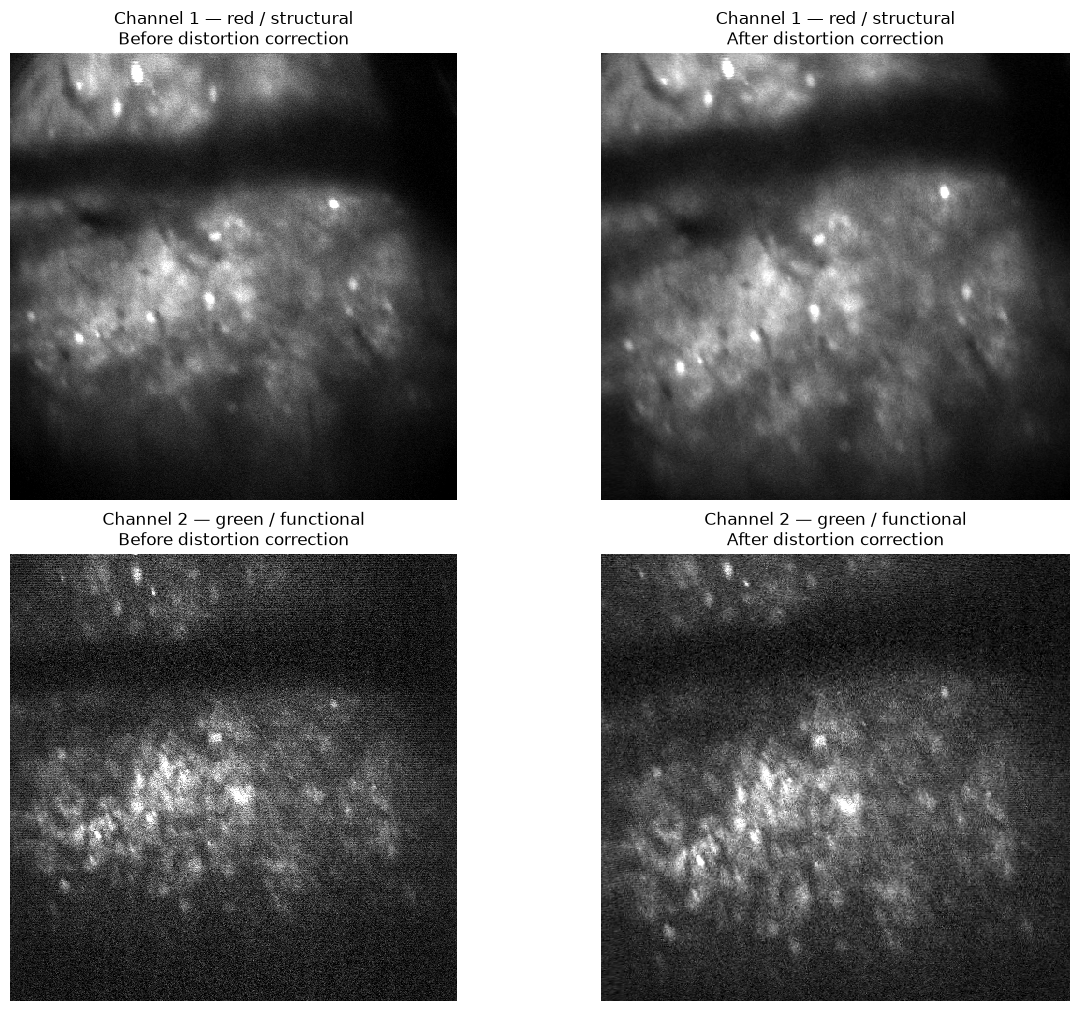

Distortion QC uses timepoints 0:100
Distortion output shape: (478, 501)


In [13]:
if IS_BATCH_WORKER:
    print('Batch worker skipped: distortion QC')
else:
    def plot_distortion_qc(before_stacks, after_stacks):
        fig, axes = plt.subplots(N_CHANNELS, 2, figsize=(12, 5 * N_CHANNELS),
                                 constrained_layout=True, squeeze=False)
        for channel_zero_based in range(N_CHANNELS):
            channel_one_based = channel_zero_based + 1
            before_mean = np.mean(before_stacks[channel_zero_based], axis=0)
            after_mean = np.mean(after_stacks[channel_zero_based], axis=0)
            finite = np.concatenate([before_mean[np.isfinite(before_mean)],
                                     after_mean[np.isfinite(after_mean)]])
            vmin, vmax = np.percentile(finite, [1, 99.8])
            for ax, image, title in zip(
                    axes[channel_zero_based], [before_mean, after_mean],
                    ['Before distortion correction', 'After distortion correction']):
                ax.imshow(image, cmap='gray', vmin=vmin, vmax=vmax,
                          interpolation='nearest')
                ax.set_title(f'{CHANNEL_NAMES[channel_one_based]}\n{title}')
                ax.axis('off')
        plt.show()


    if USE_DISTORTION_CORRECTED_INPUT:
        with tifffile.TiffFile(CORRECTED_TIFF) as before_tif, \
                tifffile.TiffFile(DISTORTION_CORRECTED_TIFF) as after_tif:
            before_n = len(before_tif.pages) // N_CHANNELS
            after_n = len(after_tif.pages) // N_CHANNELS
            qc_count = min(int(QC_DISTORTION_FRAMES), before_n, after_n)
            before_distortion = [
                read_channel_chunk(before_tif, 0, qc_count, channel, N_CHANNELS)
                for channel in range(N_CHANNELS)]
            after_distortion = [
                read_channel_chunk(after_tif, 0, qc_count, channel, N_CHANNELS)
                for channel in range(N_CHANNELS)]
        plot_distortion_qc(before_distortion, after_distortion)
        print(f'Distortion QC uses timepoints 0:{qc_count}')
        print('Distortion output shape:', after_distortion[0].shape[1:])
    else:
        print('Using the non-distortion-corrected TIFF; distortion QC skipped.')


## Suite2p motion registration

Suite2p's own `do_bidiphase` is explicitly disabled because the phase has already been corrected. `MOTION_ALIGNMENT_SOURCE` independently controls which channel supplies the motion shifts; those shifts are applied to both channels. `PHASE_ALIGNMENT_SOURCE` does not affect motion registration. Green remains the functional channel used for ROI detection and trace extraction. With `RUN_ROI_DETECTION=False`, `roidetect=False` runs registration without cell detection.

In [14]:
from suite2p import default_settings
from suite2p.run_s2p import run_s2p

# Suite2p >= 1.0 uses nested settings. In this API, default_ops is a
# module, which is why calling default_ops() raises a TypeError.
settings = default_settings()
settings['fs'] = FS_HZ
settings['diameter'] = DIAMETER_PX
settings['registration'].update({
    # True selects Suite2p's non-functional binary as the alignment source.
    'align_by_chan2': REGISTRATION_CHANNEL != FUNCTIONAL_CHANNEL,
    # Already corrected separately for every short chunk above.
    'do_bidiphase': False,
    'bidiphase': 0,
    'nonrigid': DO_NONRIGID,
    'norm_frames': NORMALIZE_REGISTRATION_FRAMES,
    'nimg_init': NIMG_INIT,
    'th_badframes': BAD_FRAME_THRESHOLD,
    'two_step_registration': TWO_STEP_REGISTRATION,
    'batch_size': REGISTRATION_BATCH_SIZE,
})
settings['run'].update({
    'do_registration': 1,
    'do_detection': RUN_ROI_DETECTION,
    'do_deconvolution': RUN_ROI_DETECTION,
})
settings['io']['save_mat'] = False

# Reconstruct the selected input when this cell is run after a kernel restart.
# local_batched still requires its distortion-writing cell to have completed.
if 'DISTORTION_MODE' not in globals():
    raise RuntimeError('Run the initial settings cell before Suite2p registration')
if DISTORTION_MODE not in {'local_batched', 'cluster_full', 'off'}:
    raise ValueError(
        "DISTORTION_MODE must be 'local_batched', 'cluster_full', or 'off'")
SUITE2P_INPUT_TIFF = (
    CORRECTED_TIFF if DISTORTION_MODE == 'off'
    else DISTORTION_CORRECTED_TIFF)
if not SUITE2P_INPUT_TIFF.is_file():
    raise FileNotFoundError(
        f'Selected Suite2p input does not exist: {SUITE2P_INPUT_TIFF}. '
        'Run the distortion cell first or choose DISTORTION_MODE=\'off\'.')

# This Suite2p API uses file_list (not the older tiff_list key). Without
# file_list, Suite2p discovers every TIFF in OUTPUT_DIR and may mix the
# uncropped 512x512 TIFF with the cropped distortion-corrected TIFF.
db = {
    'data_path': [str(OUTPUT_DIR)],
    'file_list': [SUITE2P_INPUT_TIFF.name],
    'look_one_level_down': False,
    'save_path0': str(OUTPUT_DIR),
    'save_folder': SUITE2P_SAVE_FOLDER,
    'nplanes': 1,
    'nchannels': N_CHANNELS,
    'functional_chan': FUNCTIONAL_CHANNEL,
    'keep_movie_raw': KEEP_RAW_BINARY,
}
print('Suite2p explicit file_list:', db['file_list'])
with tifffile.TiffFile(SUITE2P_INPUT_TIFF) as selected_tif:
    selected_page_shape = tuple(selected_tif.pages[0].shape)
    print('Selected TIFF page shape:', selected_page_shape)
    print('Selected TIFF pages:', len(selected_tif.pages))
existing_plane_dir = OUTPUT_DIR / SUITE2P_SAVE_FOLDER / 'plane0'
existing_db_path = OUTPUT_DIR / SUITE2P_SAVE_FOLDER / 'db.npy'
if existing_db_path.is_file():
    existing_db = np.load(existing_db_path, allow_pickle=True).item()
    existing_files = [Path(path).name for path in existing_db.get('file_list', [])]
    if existing_files != [SUITE2P_INPUT_TIFF.name]:
        raise RuntimeError(
            'The existing Suite2p folder was created from a different or mixed '
            f'file list: {existing_files}. Move the folder first: '
            f'{OUTPUT_DIR / SUITE2P_SAVE_FOLDER}')
existing_ops_path = existing_plane_dir / 'ops.npy'
if existing_ops_path.is_file():
    existing_ops = np.load(existing_ops_path, allow_pickle=True).item()
    existing_shape = (int(existing_ops['Ly']), int(existing_ops['Lx']))
    if existing_shape != selected_page_shape:
        raise RuntimeError(
            f'Existing Suite2p shape {existing_shape} does not match selected TIFF '
            f'{selected_page_shape}. Move {OUTPUT_DIR / SUITE2P_SAVE_FOLDER} '
            'before rerunning.')
suite2p_db_paths = run_s2p(settings=settings, db=db)
print('Suite2p output:', OUTPUT_DIR / SUITE2P_SAVE_FOLDER / 'plane0')

Suite2p explicit file_list: ['71rtask_00040_dynamic_bidiphase_undistorted.tif']
Selected TIFF page shape: (478, 501)
Selected TIFF pages: 28500


Suite2p output: /Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/run-02/without_destriping/suite2p/plane0


## QC 4 — Suite2p registration, before and after

This compares a mean from the phase-corrected/destriped TIFF with Suite2p's registered mean image for both channels. The same display limits are used within each channel. Motion registration may crop or darken unstable edge pixels; concentrate on whether cells and vessels become sharper in the interior.

Functional registered binary: /Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/run-02/without_destriping/suite2p/plane0/data.bin
Structural registered binary: /Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/run-02/without_destriping/suite2p/plane0/data_chan2.bin


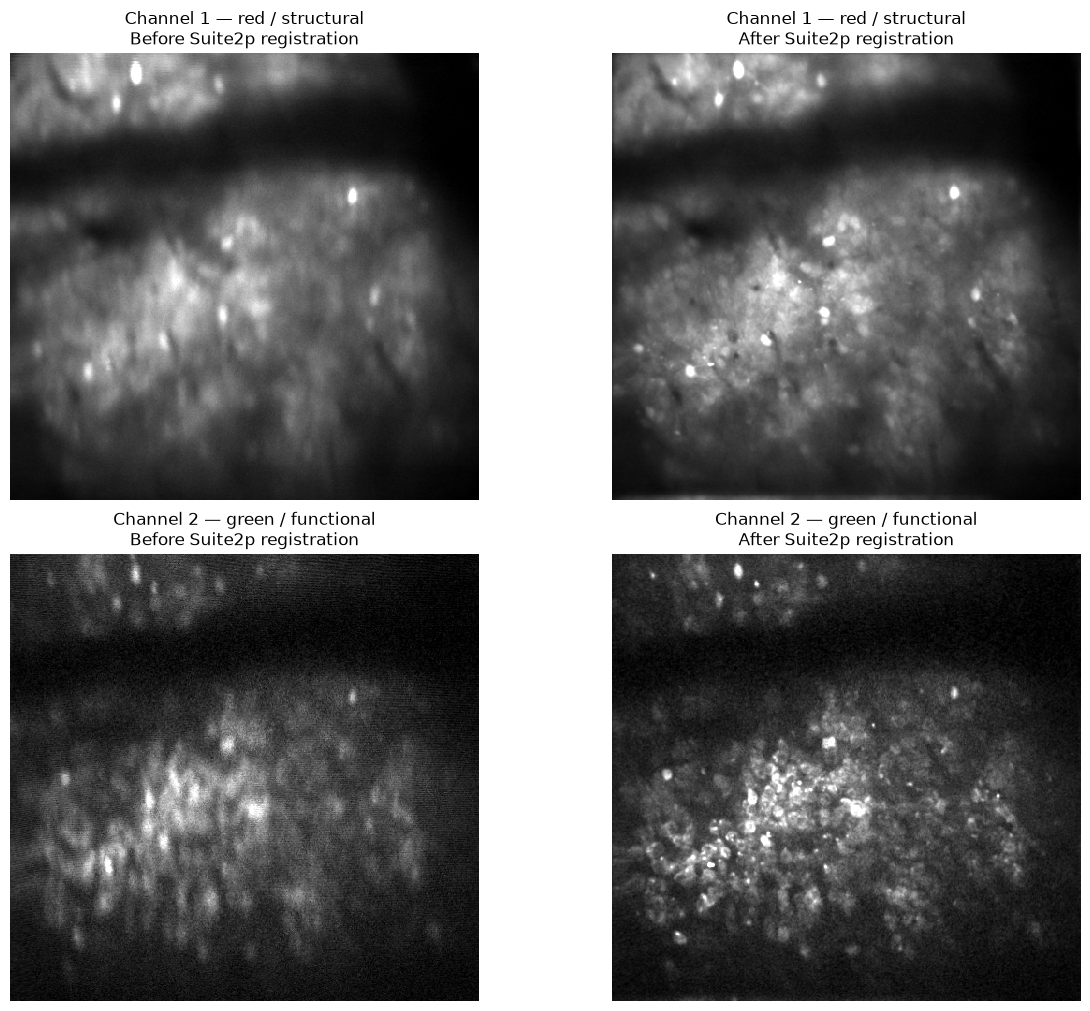

In [15]:
if IS_BATCH_WORKER:
    print('Batch worker skipped: registration before/after QC')
else:
    plane_dir = OUTPUT_DIR / SUITE2P_SAVE_FOLDER / 'plane0'
    registered_ops = np.load(plane_dir / 'ops.npy', allow_pickle=True).item()

    with tifffile.TiffFile(SUITE2P_INPUT_TIFF) as tif:
        n_timepoints = len(tif.pages) // N_CHANNELS
        mean_count = min(int(QC_REGISTRATION_FRAMES), n_timepoints)
        before_registration = [
            read_channel_chunk(tif, 0, mean_count, channel, N_CHANNELS)
            for channel in range(N_CHANNELS)
        ]

    def resolve_registered_binary(ops_key, filename):
        # Binary files can live outside save_folder when Suite2p uses fast_disk
        # or reuses an existing conversion. Trust the path saved in ops first.
        candidates = []
        saved_path = registered_ops.get(ops_key)
        if saved_path:
            candidates.append(Path(saved_path))
        candidates.extend([
            plane_dir / filename,
            OUTPUT_DIR / 'suite2p' / 'plane0' / filename,
        ])
        for candidate in candidates:
            if candidate.is_file():
                return candidate
        raise FileNotFoundError(
            f'Could not find {filename}. Checked: ' +
            ', '.join(str(candidate) for candidate in candidates)
        )

    functional_binary_path = resolve_registered_binary('reg_file', 'data.bin')
    structural_binary_path = resolve_registered_binary('reg_file_chan2', 'data_chan2.bin')
    print('Functional registered binary:', functional_binary_path)
    print('Structural registered binary:', structural_binary_path)

    Ly, Lx = int(registered_ops['Ly']), int(registered_ops['Lx'])
    functional_binary = np.memmap(functional_binary_path, dtype=np.int16, mode='r',
                                  shape=(int(registered_ops['nframes']), Ly, Lx))
    structural_binary = np.memmap(structural_binary_path, dtype=np.int16, mode='r',
                                  shape=(int(registered_ops['nframes']), Ly, Lx))
    # Use the same initial frames on both sides of the comparison. Suite2p calls
    # the functional binary data.bin and the other binary data_chan2.bin.
    registered_mean_by_channel = {
        FUNCTIONAL_CHANNEL: np.mean(functional_binary[:mean_count], axis=0),
        STRUCTURAL_CHANNEL: np.mean(structural_binary[:mean_count], axis=0),
    }
    registered_stacks = [registered_mean_by_channel[channel][None, ...]
                         for channel in range(1, N_CHANNELS + 1)]
    plot_before_after(before_registration, registered_stacks, 'Suite2p registration')


## Registration parameters and diagnostics

This cell prints the most relevant effective values saved in `ops.npy`, then plots rigid X/Y displacement, frame-to-reference correlation, and Suite2p bad-frame flags over the complete recording. When nonrigid offsets are available, their median across spatial blocks is also shown.

The second figure compares the first-`QC_REGISTRATION_FRAMES` registered-binary mean used by QC 4 with Suite2p's stored recording-wide mean used by the contrast cell. Differences between those images reflect frame selection and recording duration, not an extra contrast-cell registration step.


Motion alignment source: functional (channel 2)
Biphase alignment source: functional (channel 2)
ops.npy: /Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/run-02/without_destriping/suite2p/plane0/ops.npy
                      fs: 7.52
                 nframes: 14250
                      Ly: 478
                      Lx: 501
               nchannels: 2
         functional_chan: 2
               bidiphase: 0
              batch_size: 500


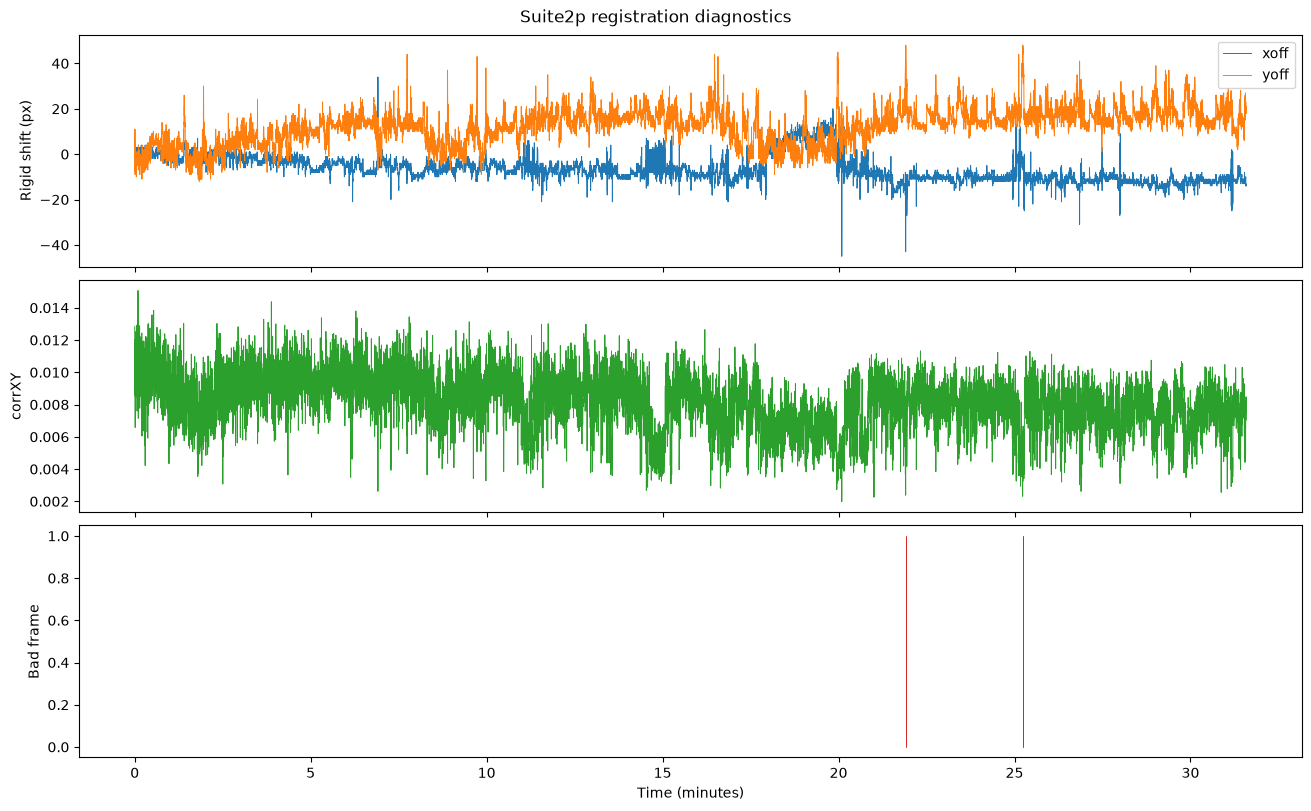

Bad frames: 5/14250


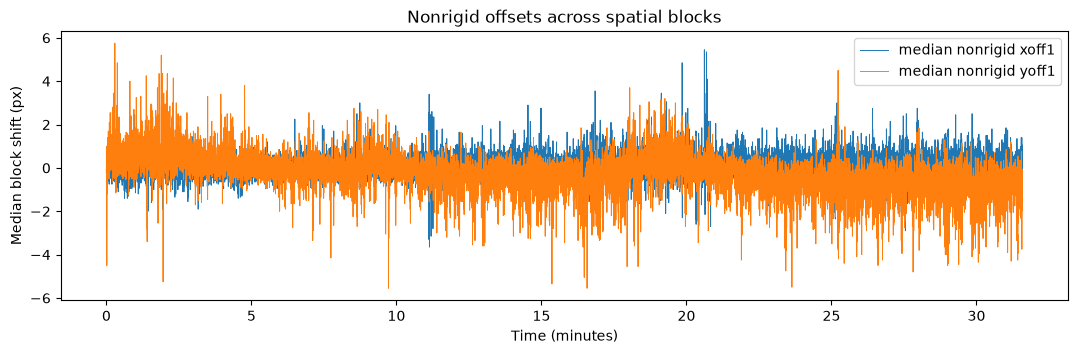

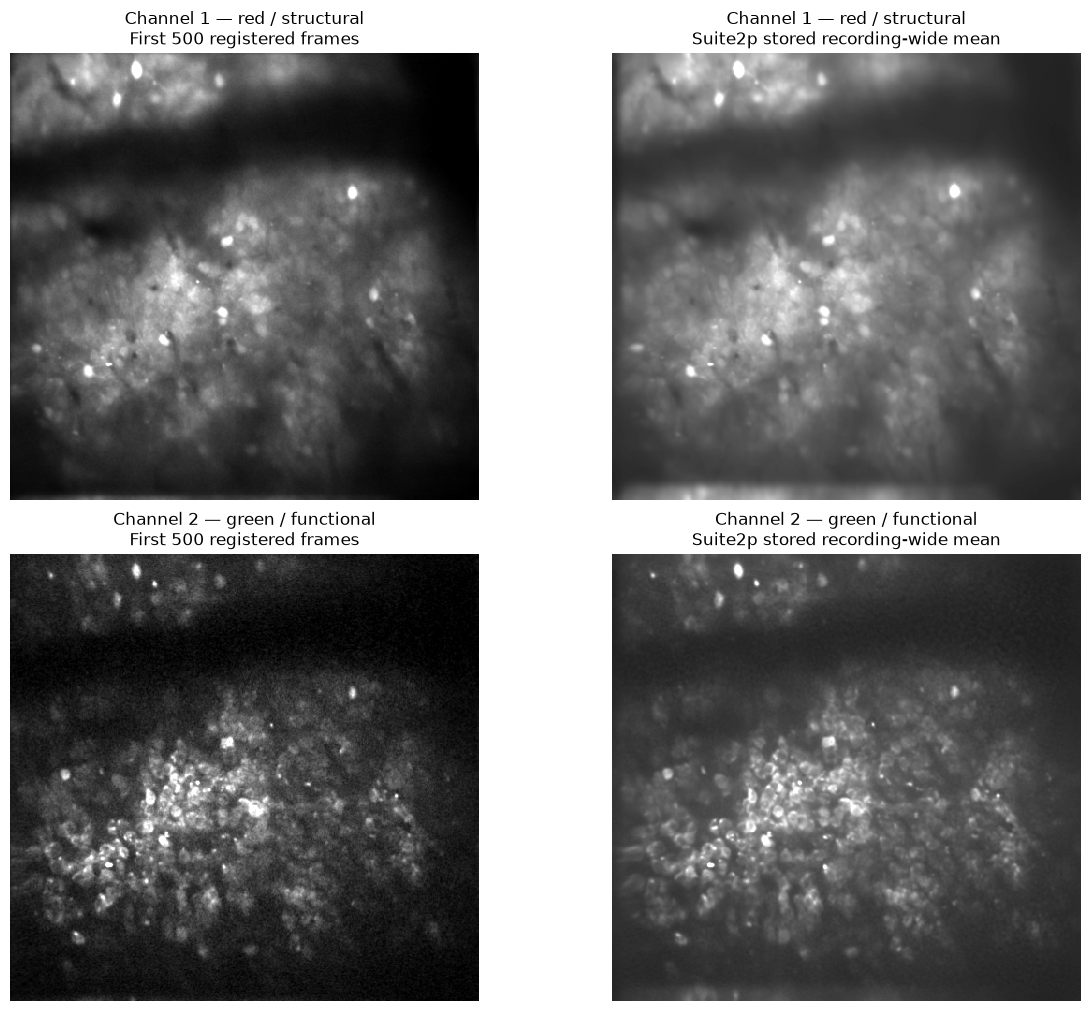

In [16]:
if IS_BATCH_WORKER:
    print('Batch worker skipped: registration diagnostic plots')
else:
    registration_parameter_keys = [
        'fs', 'nframes', 'Ly', 'Lx', 'nchannels', 'functional_chan',
        'align_by_chan2', 'do_bidiphase', 'bidiphase', 'nonrigid',
        'block_size', 'maxregshift', 'maxregshiftNR', 'smooth_sigma',
        'smooth_sigma_time', 'nimg_init', 'batch_size', 'two_step_registration',
        'norm_frames', 'th_badframes', 'snr_thresh',
    ]
    print('Motion alignment source:', MOTION_ALIGNMENT_SOURCE,
          f'(channel {REGISTRATION_CHANNEL})')
    print('Biphase alignment source:', PHASE_ALIGNMENT_SOURCE,
          f'(channel {PHASE_ALIGNMENT_CHANNEL})')
    print('ops.npy:', plane_dir / 'ops.npy')
    for key in registration_parameter_keys:
        if key in registered_ops:
            print(f'{key:>24}: {registered_ops[key]}')

    xoff = np.asarray(registered_ops.get('xoff', []), dtype=float).ravel()
    yoff = np.asarray(registered_ops.get('yoff', []), dtype=float).ravel()
    corr_xy = np.asarray(registered_ops.get('corrXY', []), dtype=float).ravel()
    badframes = np.asarray(
        registered_ops.get('badframes', np.zeros(len(xoff), dtype=bool)),
        dtype=bool).ravel()
    n_trace = min(len(xoff), len(yoff))
    if n_trace == 0:
        print('No rigid registration traces were found in ops.npy.')
    else:
        frame_index = np.arange(n_trace)
        time_minutes = frame_index / float(FS_HZ) / 60
        fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True,
                                 constrained_layout=True)
        axes[0].plot(time_minutes, xoff[:n_trace], linewidth=0.7, label='xoff')
        axes[0].plot(time_minutes, yoff[:n_trace], linewidth=0.7, label='yoff')
        axes[0].set_ylabel('Rigid shift (px)')
        axes[0].legend(loc='upper right')
        if len(corr_xy):
            axes[1].plot(time_minutes[:len(corr_xy)], corr_xy[:n_trace],
                         color='tab:green', linewidth=0.7)
        axes[1].set_ylabel('corrXY')
        if len(badframes):
            bad_index = np.flatnonzero(badframes[:n_trace])
            axes[2].vlines(time_minutes[bad_index], 0, 1, color='tab:red', linewidth=0.7)
        axes[2].set_ylim(-0.05, 1.05)
        axes[2].set_ylabel('Bad frame')
        axes[2].set_xlabel('Time (minutes)')
        fig.suptitle('Suite2p registration diagnostics')
        plt.show()
        print(f'Bad frames: {int(np.sum(badframes[:n_trace]))}/{n_trace}')

        xoff1 = np.asarray(registered_ops.get('xoff1', []), dtype=float)
        yoff1 = np.asarray(registered_ops.get('yoff1', []), dtype=float)
        if xoff1.ndim >= 2 and yoff1.ndim >= 2 and len(xoff1) == n_trace:
            plt.figure(figsize=(13, 3.5))
            plt.plot(time_minutes, np.nanmedian(xoff1, axis=1), linewidth=0.7,
                     label='median nonrigid xoff1')
            plt.plot(time_minutes, np.nanmedian(yoff1, axis=1), linewidth=0.7,
                     label='median nonrigid yoff1')
            plt.xlabel('Time (minutes)')
            plt.ylabel('Median block shift (px)')
            plt.title('Nonrigid offsets across spatial blocks')
            plt.legend()
            plt.show()

    # Directly compare the two mean-image sources with matched limits per channel.
    ops_mean_by_channel = {
        FUNCTIONAL_CHANNEL: np.squeeze(
            np.asarray(registered_ops['meanImg'], dtype=np.float32)),
        STRUCTURAL_CHANNEL: np.squeeze(
            np.asarray(registered_ops['meanImg_chan2'], dtype=np.float32)),
    }
    fig, axes = plt.subplots(N_CHANNELS, 2, figsize=(12, 5 * N_CHANNELS),
                             constrained_layout=True, squeeze=False)
    for channel_one_based in range(1, N_CHANNELS + 1):
        first_n_mean = np.asarray(registered_mean_by_channel[channel_one_based])
        full_mean = ops_mean_by_channel[channel_one_based]
        finite = np.concatenate([first_n_mean[np.isfinite(first_n_mean)],
                                 full_mean[np.isfinite(full_mean)]])
        vmin, vmax = np.percentile(finite, [1, 99.8])
        for ax, image, title in zip(
                axes[channel_one_based - 1], [first_n_mean, full_mean],
                [f'First {mean_count} registered frames',
                 'Suite2p stored recording-wide mean']):
            ax.imshow(image, cmap='gray', vmin=vmin, vmax=vmax,
                      interpolation='nearest')
            ax.set_title(f'{CHANNEL_NAMES[channel_one_based]}\n{title}')
            ax.axis('off')
    plt.show()


## Interactive registered-mean contrast and channel overlay

These are Suite2p's mean images after registration of the cluster-generated distortion-corrected TIFF. Contrast controls affect display only. The overlay places structural signal in red and functional signal in green.


In [17]:
if IS_BATCH_WORKER:
    print('Batch worker skipped: interactive contrast controls')
else:
    # If this import fails, run: %pip install ipywidgets
    import ipywidgets as widgets
    from IPython.display import display

    mean_green_raw = np.squeeze(
        np.asarray(registered_ops['meanImg'], dtype=np.float32))
    mean_red_raw = np.squeeze(
        np.asarray(registered_ops['meanImg_chan2'], dtype=np.float32))
    print('Contrast source: Suite2p means registered after distortion correction')
    if mean_green_raw.shape != mean_red_raw.shape:
        raise ValueError(f'Mean-image shape mismatch: green {mean_green_raw.shape}, red {mean_red_raw.shape}')

    def scale_contrast(image, black_percentile, white_percentile, gamma):
        finite = image[np.isfinite(image)]
        black, white = np.percentile(finite, [black_percentile, white_percentile])
        if white <= black:
            raise ValueError('White percentile must produce a value above the black percentile')
        scaled = np.clip((image - black) / (white - black), 0, 1) ** gamma
        return scaled, float(black), float(white)

    def contrast_sliders(prefix):
        return (
            widgets.FloatSlider(value=1.0, min=0.0, max=50.0, step=0.5,
                                description=f'{prefix} black %', continuous_update=False),
            widgets.FloatSlider(value=99.8, min=90.0, max=100.0, step=0.05,
                                description=f'{prefix} white %', continuous_update=False),
            widgets.FloatSlider(value=1.0, min=0.2, max=3.0, step=0.05,
                                description=f'{prefix} gamma', continuous_update=False),
        )

    green_black, green_white, green_gamma = contrast_sliders('Green')
    red_black, red_white, red_gamma = contrast_sliders('Red')

    def preview_registered_contrast(green_black_pct, green_white_pct, green_gamma_value,
                                    red_black_pct, red_white_pct, red_gamma_value):
        if green_white_pct <= green_black_pct or red_white_pct <= red_black_pct:
            print('Each white percentile must be greater than its black percentile')
            return
        green, green_low, green_high = scale_contrast(
            mean_green_raw, green_black_pct, green_white_pct, green_gamma_value)
        red, red_low, red_high = scale_contrast(
            mean_red_raw, red_black_pct, red_white_pct, red_gamma_value)
        overlay = np.zeros((*green.shape, 3), dtype=np.float32)
        overlay[..., 0] = red
        overlay[..., 1] = green

        fig, axes = plt.subplots(1, 3, figsize=(17, 6), constrained_layout=True)
        axes[0].imshow(green, cmap='gray', vmin=0, vmax=1,
                       interpolation='nearest')
        axes[0].set_title(f'Green / functional\nvalues {green_low:.3g}–{green_high:.3g}')
        axes[1].imshow(red, cmap='gray', vmin=0, vmax=1,
                       interpolation='nearest')
        axes[1].set_title(f'Red / structural\nvalues {red_low:.3g}–{red_high:.3g}')
        axes[2].imshow(overlay, vmin=0, vmax=1, interpolation='nearest')
        axes[2].set_title('Red–green overlay')
        for ax in axes:
            ax.axis('off')
        plt.show()

    contrast_controls = widgets.HBox([
        widgets.VBox([green_black, green_white, green_gamma]),
        widgets.VBox([red_black, red_white, red_gamma]),
    ])
    contrast_preview = widgets.interactive_output(
        preview_registered_contrast,
        {
            'green_black_pct': green_black, 'green_white_pct': green_white,
            'green_gamma_value': green_gamma, 'red_black_pct': red_black,
            'red_white_pct': red_white, 'red_gamma_value': red_gamma,
        },
    )
    display(contrast_controls, contrast_preview)


Contrast source: Suite2p means registered after distortion correction


Output()

## Save registered mean images with the selected contrast

Run this after adjusting the sliders. It saves the two grayscale displays and the red–green overlay as PNG files beside `ops.npy`. It also saves the unscaled floating-point Suite2p means as TIFF files for downstream analysis.

In [18]:
if IS_BATCH_WORKER:
    print('Batch worker skipped: contrast image export')
else:
    green_display, green_low, green_high = scale_contrast(
        mean_green_raw, green_black.value, green_white.value, green_gamma.value)
    red_display, red_low, red_high = scale_contrast(
        mean_red_raw, red_black.value, red_white.value, red_gamma.value)
    overlay_display = np.zeros((*green_display.shape, 3), dtype=np.float32)
    overlay_display[..., 0] = red_display
    overlay_display[..., 1] = green_display

    contrast_paths = {
        'green PNG': plane_dir / 'meanImg_green_contrast.png',
        'red PNG': plane_dir / 'meanImg_red_contrast.png',
        'overlay PNG': plane_dir / 'meanImg_red_green_overlay.png',
        'green raw TIFF': plane_dir / 'meanImg_green_raw.tif',
        'red raw TIFF': plane_dir / 'meanImg_red_raw.tif',
    }
    plt.imsave(contrast_paths['green PNG'], green_display, cmap='gray', vmin=0, vmax=1)
    plt.imsave(contrast_paths['red PNG'], red_display, cmap='gray', vmin=0, vmax=1)
    plt.imsave(contrast_paths['overlay PNG'], overlay_display, vmin=0, vmax=1)
    tifffile.imwrite(contrast_paths['green raw TIFF'], mean_green_raw.astype(np.float32))
    tifffile.imwrite(contrast_paths['red raw TIFF'], mean_red_raw.astype(np.float32))

    contrast_metadata = {
        'green': {'black_percentile': green_black.value, 'white_percentile': green_white.value,
                  'gamma': green_gamma.value, 'black_value': green_low, 'white_value': green_high},
        'red': {'black_percentile': red_black.value, 'white_percentile': red_white.value,
                'gamma': red_gamma.value, 'black_value': red_low, 'white_value': red_high},
    }
    contrast_metadata_path = plane_dir / 'meanImg_contrast_settings.json'
    contrast_metadata_path.write_text(json.dumps(contrast_metadata, indent=2))
    for label, path in contrast_paths.items():
        print(f'Saved {label}: {path}')
    print('Saved contrast settings:', contrast_metadata_path)


Saved green PNG: /Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/run-02/without_destriping/suite2p/plane0/meanImg_green_contrast.png
Saved red PNG: /Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/run-02/without_destriping/suite2p/plane0/meanImg_red_contrast.png
Saved overlay PNG: /Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/run-02/without_destriping/suite2p/plane0/meanImg_red_green_overlay.png
Saved green raw TIFF: /Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/run-02/without_destriping/suite2p/plane0/meanImg_green_raw.tif
Saved red raw TIFF: /Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/run-02/without_destriping/suite2p/plane0/meanImg_red_raw.tif
Saved contrast settings: /Users/megyoung/mini2p-preprocessing/data/mini2p/raw/MY_71_R/run-02/run-02/without_destriping/suite2p/plane0/meanImg_contrast_settings.json


## Checks after registration

Inspect `suite2p/plane0/ops.npy`. Plot `xoff`, `yoff`, and `corrXY`, and compare `meanImg` with the corrected pre-registration mean. Large motion-offset discontinuities at the same locations as phase changes may mean `PHASE_CHUNK_FRAMES` should be reduced further.

For scan-phase QC, return to the preview plot:

- Red boundary points: increase `PHASE_MAX_SHIFT_PX` and rerun from the preview.
- Abrupt phase jumps with doubled chunk means: reduce `PHASE_CHUNK_FRAMES`, typically from 20 to 10.
- Two similarly high peaks in the score curve: inspect individual frames and consider a manual per-chunk override.
- Sharp individual frames but a doubled mean: phase or motion is changing within the averaging window.

Distortion correction now runs on the registered binaries and does not alter Suite2p motion estimates. Do not enable Suite2p's registration-stage bidiphase correction as well; the TIFF has already been corrected before destriping and registration.


## Batch processing without destriping: sessions 216–231

Run the cell below by itself from a fresh kernel. It finds every `.tif` whose filename contains `71rtask` in sessions 216 through 231, assigns `run-01`, `run-02`, etc. from the increasing acquisition number in the raw filename, and executes this complete notebook in a clean kernel for each pending file.

Set `RUN_BATCH_PREPROCESSING=False` to preview the plan, or `True` to launch (currently enabled). `BATCH_RUN_DESTRIPING=False` explicitly disables destriping in every worker. Outputs, manifests, and logs are stored in each `run-XX/without_destriping/` folder; existing destriped results do not cause these runs to be skipped. Bidiphase correction, distortion correction, and Suite2p settings are retained. Do not use **Run All** in the controller notebook: the batch cell launches the complete single-run pipeline itself. Each run receives a `source_tiff.json` manifest and an executed `preprocessing_log.ipynb`. Existing matching runs are skipped; conflicting run assignments stop safely rather than being overwritten.


In [ ]:
# MINI2P_BATCH_DRIVER_V1
from pathlib import Path
from datetime import datetime, timezone
import json
import os
import re
import shutil
import subprocess
import sys

RUN_BATCH_PREPROCESSING = True  # inspect the dry-run plan, then change to True
BATCH_RUN_DESTRIPING = False  # Explicitly applied to every worker
BATCH_OUTPUT_SUBDIR = '' if BATCH_RUN_DESTRIPING else 'without_destriping'
STOP_ON_ERROR = True
RETRY_INCOMPLETE_RUNS = True     # retries failed/interrupted, never completed runs
SESSION_FIRST = 216
SESSION_LAST = 231
RAW_SUBJECT_DIR = Path(
    '/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/'
    'cohort-01/sub-03_id-MY_71_R'
)
DERIVATIVES_SUBJECT_DIR = Path(
    '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/'
    'cohort-01/sub-03_id-MY_71_R'
)
SOURCE_SUBSTRING = '71rtask'
MANIFEST_NAME = 'source_tiff.json'

# A worker reaches this cell after executing the pipeline. It must not launch
# another copy of itself.
if os.environ.get('MINI2P_BATCH_WORKER') == '1':
    print('Batch-worker mode: nested batch launch skipped.')
else:
    notebook_candidates = [
        Path.cwd() / 'scripts' / 'mini2p_dynamic_bidiphase_destripe_suite2p.ipynb',
        Path.cwd() / 'mini2p_dynamic_bidiphase_destripe_suite2p.ipynb',
        Path('/Users/megyoung/mini2p-preprocessing/scripts/'
             'mini2p_dynamic_bidiphase_destripe_suite2p.ipynb'),
    ]
    batch_notebook = next(
        (candidate.resolve() for candidate in notebook_candidates
         if candidate.is_file()), None)
    if batch_notebook is None:
        raise FileNotFoundError('Could not locate the mini2p preprocessing notebook')

    session_pattern = re.compile(r'^ses-(\d+)_')
    acquisition_pattern = re.compile(r'(\d+)$')

    def acquisition_key(tiff_path):
        """Sort ScanImage names by their trailing acquisition counter."""
        match = acquisition_pattern.search(tiff_path.stem)
        if match:
            return (0, int(match.group(1)), tiff_path.name.lower())
        # Deterministic fallback for an unexpected filename without a counter.
        return (1, tiff_path.name.lower(), tiff_path.stat().st_mtime_ns)

    def source_identity(tiff_path):
        stat = tiff_path.stat()
        return {
            'source_tiff': str(tiff_path.resolve()),
            'source_size_bytes': int(stat.st_size),
            'source_mtime_ns': int(stat.st_mtime_ns),
        }

    def read_json(json_path):
        try:
            return json.loads(json_path.read_text())
        except (OSError, ValueError, TypeError):
            return None

    def infer_existing_source(run_dir):
        """Recover source identity from a manifest or older phase sidecar."""
        manifest = read_json(run_dir / MANIFEST_NAME)
        if manifest and manifest.get('source_tiff'):
            return Path(manifest['source_tiff']).resolve(), manifest, 'manifest'
        for sidecar in sorted(run_dir.glob('*.phase.json')):
            phase = read_json(sidecar)
            if phase and phase.get('input_tiff'):
                return Path(phase['input_tiff']).resolve(), phase, 'phase sidecar'
        return None, None, None

    sessions = []
    for directory in RAW_SUBJECT_DIR.iterdir():
        if not directory.is_dir():
            continue
        match = session_pattern.match(directory.name)
        if match and SESSION_FIRST <= int(match.group(1)) <= SESSION_LAST:
            sessions.append((int(match.group(1)), directory))
    sessions.sort()
    found_numbers = {number for number, _ in sessions}
    missing_sessions = [
        number for number in range(SESSION_FIRST, SESSION_LAST + 1)
        if number not in found_numbers]
    if missing_sessions:
        raise FileNotFoundError(f'Missing raw session directories: {missing_sessions}')

    plan = []
    conflicts = []
    for session_number, session_dir in sessions:
        raw_funcimg = session_dir / 'funcimg'
        files = sorted(
            (item for item in raw_funcimg.iterdir()
             if item.is_file() and item.suffix.lower() == '.tif'
             and SOURCE_SUBSTRING.lower() in item.name.lower()),
            key=acquisition_key,
        )
        derivative_funcimg = DERIVATIVES_SUBJECT_DIR / session_dir.name / 'funcimg'

        # Detect the same raw TIFF already assigned to any run, even if an older
        # run number differs from today's deterministic chronological assignment.
        existing_source_to_run = {}
        if derivative_funcimg.is_dir():
            for existing_run in sorted(derivative_funcimg.glob('run-*')):
                if not existing_run.is_dir():
                    continue
                existing_source, existing_metadata, evidence = infer_existing_source(
                    existing_run / BATCH_OUTPUT_SUBDIR)
                if existing_source is not None:
                    existing_source_to_run[existing_source] = (
                        existing_run / BATCH_OUTPUT_SUBDIR, existing_metadata, evidence)

        for run_index, source_tiff in enumerate(files, start=1):
            base_run_dir = derivative_funcimg / f'run-{run_index:02d}'
            run_dir = base_run_dir / BATCH_OUTPUT_SUBDIR
            identity = source_identity(source_tiff)
            source_resolved = source_tiff.resolve()
            action = 'run'
            reason = 'new source/run assignment'

            prior_elsewhere = existing_source_to_run.get(source_resolved)
            if prior_elsewhere and prior_elsewhere[0] != run_dir:
                prior_run, prior_metadata, evidence = prior_elsewhere
                action = 'skip'
                reason = f'already assigned to {prior_run.name} ({evidence})'
            elif run_dir.exists():
                prior_source, prior_metadata, evidence = infer_existing_source(run_dir)
                if prior_source is None:
                    action = 'conflict'
                    reason = 'run directory exists but its source cannot be identified'
                elif prior_source != source_resolved:
                    action = 'conflict'
                    reason = f'run directory belongs to {prior_source.name} ({evidence})'
                else:
                    status = prior_metadata.get('status') if evidence == 'manifest' else None
                    if evidence == 'manifest':
                        same_snapshot = (
                            prior_metadata.get('source_size_bytes') == identity['source_size_bytes']
                            and prior_metadata.get('source_mtime_ns') == identity['source_mtime_ns'])
                        if not same_snapshot:
                            action = 'conflict'
                            reason = 'source path matches but file size/mtime changed'
                        elif status == 'complete':
                            action = 'skip'
                            reason = 'completed manifest already exists'
                        elif RETRY_INCOMPLETE_RUNS and status in {'failed', 'interrupted'}:
                            action = 'run'
                            reason = f'retrying manifest status={status}'
                        else:
                            action = 'skip'
                            reason = f'existing manifest status={status or "unknown"}'
                    else:
                        action = 'skip'
                        reason = f'matching older output found via {evidence}'

            row = {
                'session': session_number, 'source': source_tiff,
                'run_dir': run_dir, 'action': action, 'reason': reason,
                'identity': identity, 'run_name': base_run_dir.name,
            }
            plan.append(row)
            if action == 'conflict':
                conflicts.append(row)

    print(f'Notebook: {batch_notebook}')
    print(f'Destriping enabled: {BATCH_RUN_DESTRIPING}; output subfolder: {BATCH_OUTPUT_SUBDIR or "(run root)"}')
    print(f'Found {len(plan)} matching TIFFs across {len(sessions)} sessions.')
    print(f'{"session":>7}  {"run":>6}  {"action":>8}  source / reason')
    for row in plan:
        print(f'{row["session"]:>7}  {row["run_name"]:>6}  '
              f'{row["action"]:>8}  {row["source"].name} — {row["reason"]}')
    print('Summary:', {
        action: sum(row['action'] == action for row in plan)
        for action in ('run', 'skip', 'conflict')})

    if conflicts:
        details = '\n'.join(
            f'  {row["run_dir"]}: {row["reason"]}' for row in conflicts)
        print('CONFLICTS TO RESOLVE BEFORE LAUNCHING:\n' + details)
        if RUN_BATCH_PREPROCESSING:
            raise RuntimeError(
                'Resolve existing run-directory conflicts before launching.')

    if not RUN_BATCH_PREPROCESSING:
        print('DRY RUN ONLY. Set RUN_BATCH_PREPROCESSING=True after checking the plan.')
    else:
        pending = [row for row in plan if row['action'] == 'run']
        print(f'Starting {len(pending)} pending preprocessing runs sequentially.')
        for job_index, row in enumerate(pending, start=1):
            run_dir = row['run_dir']
            run_dir.mkdir(parents=True, exist_ok=True)
            manifest_path = run_dir / MANIFEST_NAME
            manifest = {
                **row['identity'],
                'session': row['session'],
                'run': row['run_name'],
                'destriping_enabled': BATCH_RUN_DESTRIPING,
                'output_dir': str(run_dir),
                'status': 'running',
                'started_utc': datetime.now(timezone.utc).isoformat(),
                'pipeline_notebook': str(batch_notebook),
            }
            manifest_path.write_text(json.dumps(manifest, indent=2))
            executed_notebook = run_dir / 'preprocessing_log.ipynb'
            worker_log_path = run_dir / 'nbconvert.log'

            # nbconvert otherwise follows the notebook's generic `python3`
            # kernelspec, which may point to base Conda rather than this kernel.
            # Register a private, run-local kernelspec using this exact Python.
            kernel_root = run_dir / '.jupyter'
            kernel_name = 'mini2p-batch-worker'
            kernel_dir = kernel_root / 'kernels' / kernel_name
            kernel_dir.mkdir(parents=True, exist_ok=True)
            (kernel_dir / 'kernel.json').write_text(json.dumps({
                'argv': [sys.executable, '-m', 'ipykernel_launcher',
                         '-f', '{connection_file}'],
                'display_name': 'mini2p batch worker',
                'language': 'python',
            }, indent=2))

            worker_environment = os.environ.copy()
            existing_jupyter_path = worker_environment.get('JUPYTER_PATH')
            worker_environment['JUPYTER_PATH'] = (
                str(kernel_root) if not existing_jupyter_path
                else str(kernel_root) + os.pathsep + existing_jupyter_path)
            worker_environment.update({
                'MINI2P_BATCH_WORKER': '1',
                'MINI2P_RUN_DESTRIPING': '1' if BATCH_RUN_DESTRIPING else '0',
                'MINI2P_WORKER_INPUT_TIFF': str(row['source'].resolve()),
                'MINI2P_WORKER_OUTPUT_DIR': str(run_dir.resolve()),
            })
            # nbconvert need not be installed in the analysis environment.
            # Use its executable from PATH or the parent Conda installation;
            # the private kernelspec above still runs cells with sys.executable.
            conda_base_nbconvert = (
                Path(sys.executable).parents[3] / 'bin' / 'jupyter-nbconvert')
            nbconvert_executable = shutil.which('jupyter-nbconvert')
            if nbconvert_executable is None and conda_base_nbconvert.is_file():
                nbconvert_executable = str(conda_base_nbconvert)
            if nbconvert_executable is None:
                raise FileNotFoundError(
                    'jupyter-nbconvert was not found on PATH or in the parent Conda installation')
            command = [
                nbconvert_executable,
                '--to', 'notebook', '--execute', str(batch_notebook),
                '--output', executed_notebook.name,
                '--output-dir', str(run_dir),
                '--ExecutePreprocessor.timeout=-1',
                f'--ExecutePreprocessor.kernel_name={kernel_name}',
            ]
            print(f'[{job_index}/{len(pending)}] {row["source"]} -> {run_dir}')
            try:
                with worker_log_path.open('w') as worker_log:
                    subprocess.run(
                        command, check=True, env=worker_environment,
                        stdout=worker_log, stderr=subprocess.STDOUT,
                        text=True)
            except subprocess.CalledProcessError as exc:
                child_output = worker_log_path.read_text() if worker_log_path.exists() else ''
                error_tail = '\n'.join(child_output.splitlines()[-80:])
                manifest.update({
                    'status': 'failed',
                    'finished_utc': datetime.now(timezone.utc).isoformat(),
                    'error': repr(exc),
                    'worker_log': str(worker_log_path),
                    'error_tail': error_tail,
                })
                manifest_path.write_text(json.dumps(manifest, indent=2))
                print(f'FAILED: {row["source"]}')
                print(error_tail)
                if STOP_ON_ERROR:
                    raise RuntimeError(
                        f'Worker failed; full log saved at {worker_log_path}') from exc
            except KeyboardInterrupt:
                manifest.update({
                    'status': 'interrupted',
                    'finished_utc': datetime.now(timezone.utc).isoformat(),
                    'worker_log': str(worker_log_path),
                })
                manifest_path.write_text(json.dumps(manifest, indent=2))
                raise
            else:
                manifest.update({
                    'status': 'complete',
                    'finished_utc': datetime.now(timezone.utc).isoformat(),
                    'executed_notebook': str(executed_notebook),
                })
                manifest_path.write_text(json.dumps(manifest, indent=2))
                print(f'COMPLETE: {run_dir}')
        print('Batch preprocessing finished.')


Notebook: /Users/megyoung/mini2p-preprocessing/scripts/mini2p_dynamic_bidiphase_destripe_suite2p.ipynb
Destriping enabled: False; output subfolder: without_destriping
Found 68 matching TIFFs across 16 sessions.
session     run    action  source / reason
    216  run-01       run  71rtask_00001.tif — new source/run assignment
    216  run-02       run  71rtask_00002.tif — new source/run assignment
    216  run-03       run  71rtask_00003.tif — new source/run assignment
    216  run-04       run  71rtask_00004.tif — new source/run assignment
    216  run-05       run  71rtask_00005.tif — new source/run assignment
    216  run-06       run  71rtask_00006.tif — new source/run assignment
    216  run-07       run  71rtask_00007.tif — new source/run assignment
    217  run-01       run  71rtask_00008.tif — new source/run assignment
    217  run-02       run  71rtask_00009.tif — new source/run assignment
    217  run-03       run  71rtask_00010.tif — new source/run assignment
    218  run-01 

python(15555) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


## Export raw and fixed-contrast Suite2p mean images for all runs

Run the following cell by itself after batch preprocessing has finished. It requires exactly 68 Suite2p outputs in sessions 216–231, then saves raw floating-point TIFFs, independently contrast-adjusted grayscale PNGs, a red/green contrast overlay, and a JSON record of the display settings for every run.


In [3]:
# BATCH_MEAN_IMAGE_EXPORT_V1
from pathlib import Path
import json
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import tifffile

MEAN_EXPORT_SUBJECT_DIR = Path(
    '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/'
    'cohort-01/sub-03_id-MY_71_R'
)
MEAN_EXPORT_SESSION_FIRST = 216
MEAN_EXPORT_SESSION_LAST = 231
MEAN_EXPORT_EXPECTED_RUNS = 68
MEAN_EXPORT_REQUIRE_EXPECTED_COUNT = True
MEAN_EXPORT_BLACK_PERCENTILE = 5.0
MEAN_EXPORT_WHITE_PERCENTILE = 99.5
MEAN_EXPORT_GAMMA = 1.2
MEAN_EXPORT_OVERWRITE = False  # existing files are reported and left unchanged


def fixed_mean_contrast(image, black_percentile, white_percentile, gamma):
    image = np.squeeze(np.asarray(image, dtype=np.float32))
    if image.ndim != 2:
        raise ValueError(f'Expected a 2D mean image, received shape {image.shape}')
    finite = image[np.isfinite(image)]
    if finite.size == 0:
        raise ValueError('Mean image contains no finite pixels')
    black, white = np.percentile(
        finite, [black_percentile, white_percentile])
    if white <= black:
        raise ValueError(
            f'Invalid contrast values: black={black}, white={white}')
    adjusted = np.clip((image - black) / (white - black), 0, 1) ** gamma
    adjusted[~np.isfinite(adjusted)] = 0
    return image, adjusted.astype(np.float32), float(black), float(white)


def save_unless_present(output_path, save_function):
    if output_path.exists() and not MEAN_EXPORT_OVERWRITE:
        return 'existing'
    save_function(output_path)
    return 'saved'


if os.environ.get('MINI2P_BATCH_WORKER') == '1':
    print('Batch worker skipped: cross-run mean-image export')
else:
    session_pattern = re.compile(r'^ses-(\d+)_')
    plane_dirs = []
    for session_dir in sorted(MEAN_EXPORT_SUBJECT_DIR.glob('ses-*')):
        match = session_pattern.match(session_dir.name)
        if not match:
            continue
        session_number = int(match.group(1))
        if not MEAN_EXPORT_SESSION_FIRST <= session_number <= MEAN_EXPORT_SESSION_LAST:
            continue
        for run_dir in sorted((session_dir / 'funcimg').glob('run-*')):
            ops_path = run_dir / 'suite2p' / 'plane0' / 'ops.npy'
            if ops_path.is_file():
                plane_dirs.append((session_number, run_dir.name, ops_path.parent))

    print(f'Found {len(plane_dirs)} Suite2p plane directories.')
    if (MEAN_EXPORT_REQUIRE_EXPECTED_COUNT
            and len(plane_dirs) != MEAN_EXPORT_EXPECTED_RUNS):
        raise RuntimeError(
            f'Expected {MEAN_EXPORT_EXPECTED_RUNS} runs but found {len(plane_dirs)}. '
            'No mean images were exported; inspect missing or extra runs first.')

    export_summary = []
    for export_index, (session_number, run_name, plane_dir) in enumerate(
            plane_dirs, start=1):
        ops_path = plane_dir / 'ops.npy'
        ops = np.load(ops_path, allow_pickle=True).item()
        missing_keys = [
            key for key in ('meanImg', 'meanImg_chan2') if key not in ops]
        if missing_keys:
            raise KeyError(f'{ops_path} is missing {missing_keys}')

        # With functional_chan=2, Suite2p stores physical green channel 2 in
        # meanImg and the other (physical red channel 1) in meanImg_chan2.
        green_raw, green_display, green_black, green_white = fixed_mean_contrast(
            ops['meanImg'], MEAN_EXPORT_BLACK_PERCENTILE,
            MEAN_EXPORT_WHITE_PERCENTILE, MEAN_EXPORT_GAMMA)
        red_raw, red_display, red_black, red_white = fixed_mean_contrast(
            ops['meanImg_chan2'], MEAN_EXPORT_BLACK_PERCENTILE,
            MEAN_EXPORT_WHITE_PERCENTILE, MEAN_EXPORT_GAMMA)
        if green_raw.shape != red_raw.shape:
            raise ValueError(
                f'{ops_path}: mean image shapes differ: '
                f'{green_raw.shape} versus {red_raw.shape}')

        overlay = np.zeros((*green_display.shape, 3), dtype=np.float32)
        overlay[..., 0] = red_display
        overlay[..., 1] = green_display

        outputs = {
            'green raw TIFF': plane_dir / 'meanImg_green_functional_raw.tif',
            'red raw TIFF': plane_dir / 'meanImg_red_structural_raw.tif',
            'green contrast PNG': plane_dir / 'meanImg_green_functional_contrast.png',
            'red contrast PNG': plane_dir / 'meanImg_red_structural_contrast.png',
            'overlay contrast PNG': plane_dir / 'meanImg_red_green_overlay_contrast.png',
        }
        states = {}
        states['green raw TIFF'] = save_unless_present(
            outputs['green raw TIFF'],
            lambda output: tifffile.imwrite(
                output, green_raw.astype(np.float32), photometric='minisblack'))
        states['red raw TIFF'] = save_unless_present(
            outputs['red raw TIFF'],
            lambda output: tifffile.imwrite(
                output, red_raw.astype(np.float32), photometric='minisblack'))
        states['green contrast PNG'] = save_unless_present(
            outputs['green contrast PNG'],
            lambda output: plt.imsave(
                output, green_display, cmap='gray', vmin=0, vmax=1))
        states['red contrast PNG'] = save_unless_present(
            outputs['red contrast PNG'],
            lambda output: plt.imsave(
                output, red_display, cmap='gray', vmin=0, vmax=1))
        states['overlay contrast PNG'] = save_unless_present(
            outputs['overlay contrast PNG'],
            lambda output: plt.imsave(output, overlay, vmin=0, vmax=1))

        settings_path = plane_dir / 'meanImg_fixed_contrast_settings.json'
        settings_record = {
            'ops_path': str(ops_path),
            'black_percentile': MEAN_EXPORT_BLACK_PERCENTILE,
            'white_percentile': MEAN_EXPORT_WHITE_PERCENTILE,
            'gamma': MEAN_EXPORT_GAMMA,
            'green_functional_physical_channel_2': {
                'suite2p_key': 'meanImg',
                'black_value': green_black,
                'white_value': green_white,
            },
            'red_structural_physical_channel_1': {
                'suite2p_key': 'meanImg_chan2',
                'black_value': red_black,
                'white_value': red_white,
            },
            'outputs': {label: str(output) for label, output in outputs.items()},
        }
        settings_state = save_unless_present(
            settings_path,
            lambda output: output.write_text(json.dumps(settings_record, indent=2)))
        states['settings JSON'] = settings_state

        export_summary.append({
            'session': session_number,
            'run': run_name,
            'plane_dir': str(plane_dir),
            'states': states,
        })
        print(f'[{export_index:02d}/{len(plane_dirs):02d}] '
              f'ses-{session_number} {run_name}: {states}')

    summary_path = MEAN_EXPORT_SUBJECT_DIR / 'meanImg_export_summary_sessions-216-231.json'
    summary_path.write_text(json.dumps({
        'run_count': len(export_summary),
        'black_percentile': MEAN_EXPORT_BLACK_PERCENTILE,
        'white_percentile': MEAN_EXPORT_WHITE_PERCENTILE,
        'gamma': MEAN_EXPORT_GAMMA,
        'runs': export_summary,
    }, indent=2))
    print(f'Finished mean-image export for {len(export_summary)} runs.')
    print('Summary:', summary_path)


Found 68 Suite2p plane directories.
[01/68] ses-216 run-01: {'green raw TIFF': 'saved', 'red raw TIFF': 'saved', 'green contrast PNG': 'saved', 'red contrast PNG': 'saved', 'overlay contrast PNG': 'saved', 'settings JSON': 'saved'}
[02/68] ses-216 run-02: {'green raw TIFF': 'saved', 'red raw TIFF': 'saved', 'green contrast PNG': 'saved', 'red contrast PNG': 'saved', 'overlay contrast PNG': 'saved', 'settings JSON': 'saved'}
[03/68] ses-216 run-03: {'green raw TIFF': 'saved', 'red raw TIFF': 'saved', 'green contrast PNG': 'saved', 'red contrast PNG': 'saved', 'overlay contrast PNG': 'saved', 'settings JSON': 'saved'}
[04/68] ses-216 run-04: {'green raw TIFF': 'saved', 'red raw TIFF': 'saved', 'green contrast PNG': 'saved', 'red contrast PNG': 'saved', 'overlay contrast PNG': 'saved', 'settings JSON': 'saved'}
[05/68] ses-216 run-05: {'green raw TIFF': 'saved', 'red raw TIFF': 'saved', 'green contrast PNG': 'saved', 'red contrast PNG': 'saved', 'overlay contrast PNG': 'saved', 'settings 

## Create the 68-run mean-image comparison PDF

Run this cell after the batch mean-image export cell. It creates one landscape page per run, headed by session and run, with the fixed-contrast green and red images side by side. It also reports runs containing both the older interactive contrast-settings JSON and the fixed-settings JSON.


In [4]:
# MEAN_CONTRAST_PDF_V1
from pathlib import Path
import json
import os
import re

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

PDF_SUBJECT_DIR = Path(
    '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/'
    'cohort-01/sub-03_id-MY_71_R'
)
PDF_SESSION_FIRST = 216
PDF_SESSION_LAST = 231
PDF_EXPECTED_RUNS = 68
PDF_OVERWRITE = False
PDF_OUTPUT = PDF_SUBJECT_DIR / 'meanImg_contrast_sessions-216-231.pdf'

GREEN_CONTRAST_FILENAME = 'meanImg_green_functional_contrast.png'
RED_CONTRAST_FILENAME = 'meanImg_red_structural_contrast.png'
OLDER_SETTINGS_FILENAME = 'meanImg_contrast_settings.json'
FIXED_SETTINGS_FILENAME = 'meanImg_fixed_contrast_settings.json'


if os.environ.get('MINI2P_BATCH_WORKER') == '1':
    print('Batch worker skipped: 68-run mean-image PDF')
else:
    session_pattern = re.compile(r'^ses-(\d+)_')
    run_pattern = re.compile(r'^run-(\d+)$')
    pdf_runs = []
    for session_dir in PDF_SUBJECT_DIR.glob('ses-*'):
        session_match = session_pattern.match(session_dir.name)
        if not session_match:
            continue
        session_number = int(session_match.group(1))
        if not PDF_SESSION_FIRST <= session_number <= PDF_SESSION_LAST:
            continue
        for run_dir in (session_dir / 'funcimg').glob('run-*'):
            run_match = run_pattern.match(run_dir.name)
            if not run_match:
                continue
            plane_dir = run_dir / 'suite2p' / 'plane0'
            if (plane_dir / 'ops.npy').is_file():
                pdf_runs.append((
                    session_number, int(run_match.group(1)),
                    session_dir.name, run_dir.name, plane_dir))
    pdf_runs.sort(key=lambda row: (row[0], row[1]))

    if len(pdf_runs) != PDF_EXPECTED_RUNS:
        raise RuntimeError(
            f'Expected {PDF_EXPECTED_RUNS} Suite2p runs but found {len(pdf_runs)}. '
            'No PDF was created.')

    older_and_fixed = [
        (session_number, run_name)
        for session_number, _, _, run_name, plane_dir in pdf_runs
        if (plane_dir / OLDER_SETTINGS_FILENAME).is_file()
        and (plane_dir / FIXED_SETTINGS_FILENAME).is_file()
    ]
    print(f'Runs containing both settings files: {len(older_and_fixed)}')
    for session_number, run_name in older_and_fixed:
        print(f'  ses-{session_number} {run_name}')

    missing_images = []
    for session_number, _, _, run_name, plane_dir in pdf_runs:
        for filename in (GREEN_CONTRAST_FILENAME, RED_CONTRAST_FILENAME):
            image_path = plane_dir / filename
            if not image_path.is_file():
                missing_images.append(
                    f'ses-{session_number} {run_name}: {image_path}')
    if missing_images:
        raise FileNotFoundError(
            'Run the batch mean-image export cell first. Missing images:\n' +
            '\n'.join(missing_images))

    if PDF_OUTPUT.exists() and not PDF_OVERWRITE:
        raise FileExistsError(
            f'{PDF_OUTPUT} already exists. Set PDF_OVERWRITE=True to replace it.')

    with PdfPages(PDF_OUTPUT) as pdf:
        metadata = pdf.infodict()
        metadata['Title'] = 'Mini2P registered mean images, sessions 216-231'
        metadata['Author'] = 'Mini2P preprocessing pipeline'
        metadata['Subject'] = (
            'Suite2p green and red mean images; black=5%, white=99.5%, gamma=1.2')

        for page_number, (
                session_number, run_number, session_name, run_name,
                plane_dir) in enumerate(pdf_runs, start=1):
            green = plt.imread(plane_dir / GREEN_CONTRAST_FILENAME)
            red = plt.imread(plane_dir / RED_CONTRAST_FILENAME)

            fig, axes = plt.subplots(1, 2, figsize=(11.69, 7.25), facecolor='white')
            fig.subplots_adjust(
                left=0.035, right=0.965, bottom=0.075, top=0.84, wspace=0.045)
            fig.suptitle(
                f'Session {session_number} | {run_name}',
                fontsize=19, fontweight='bold', y=0.955)
            fig.text(
                0.5, 0.905,
                f'{session_name}  |  fixed contrast: black 5%, white 99.5%, gamma 1.2',
                ha='center', va='center', fontsize=10.5, color='0.30')

            axes[0].imshow(green, cmap='gray', vmin=0, vmax=1,
                           interpolation='nearest')
            axes[0].set_title(
                'Green functional\nphysical channel 2 | Suite2p meanImg',
                fontsize=12, pad=10)
            axes[1].imshow(red, cmap='gray', vmin=0, vmax=1,
                           interpolation='nearest')
            axes[1].set_title(
                'Red structural\nphysical channel 1 | Suite2p meanImg_chan2',
                fontsize=12, pad=10)
            for axis in axes:
                axis.axis('off')

            fig.text(
                0.5, 0.025, f'Page {page_number} of {len(pdf_runs)}',
                ha='center', va='bottom', fontsize=9, color='0.45')
            pdf.savefig(fig, dpi=180, facecolor='white')
            plt.close(fig)
            if page_number % 10 == 0 or page_number == len(pdf_runs):
                print(f'Added {page_number}/{len(pdf_runs)} pages')

    print('Saved 68-run mean-image PDF:', PDF_OUTPUT)


Runs containing both settings files: 0
Added 10/68 pages
Added 20/68 pages
Added 30/68 pages
Added 40/68 pages
Added 50/68 pages
Added 60/68 pages
Added 68/68 pages
Saved 68-run mean-image PDF: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/meanImg_contrast_sessions-216-231.pdf


## Create the 136-page high-resolution mean-image PDF

Run this cell by itself after preprocessing. It covers all 68 outputs in session/run order. Each run receives two portrait pages: the green functional Suite2p mean first, followed by the red structural mean. Contrast is recalculated directly from the floating-point arrays in `ops.npy` using black 5%, white 99.5%, and gamma 1.2.


In [1]:
# MEAN_CONTRAST_136_PAGE_PDF_V1
from pathlib import Path
import os
import re

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import numpy as np

HIRES_PDF_SUBJECT_DIR = Path(
    '/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/'
    'cohort-01/sub-03_id-MY_71_R'
)
HIRES_PDF_SESSION_FIRST = 216
HIRES_PDF_SESSION_LAST = 231
HIRES_PDF_EXPECTED_RUNS = 68
HIRES_PDF_EXPECTED_PAGES = 136
HIRES_PDF_BLACK_PERCENTILE = 5.0
HIRES_PDF_WHITE_PERCENTILE = 99.5
HIRES_PDF_GAMMA = 1.2
HIRES_PDF_DPI = 400
HIRES_PDF_OVERWRITE = False
HIRES_PDF_OUTPUT = (
    HIRES_PDF_SUBJECT_DIR /
    'meanImg_high_resolution_136_pages_sessions-216-231.pdf'
)


def pdf_scale_mean(image):
    image = np.squeeze(np.asarray(image, dtype=np.float32))
    if image.ndim != 2:
        raise ValueError(f'Expected a 2D mean image, received {image.shape}')
    finite = image[np.isfinite(image)]
    if finite.size == 0:
        raise ValueError('Mean image contains no finite values')
    black, white = np.percentile(
        finite,
        [HIRES_PDF_BLACK_PERCENTILE, HIRES_PDF_WHITE_PERCENTILE],
    )
    if white <= black:
        raise ValueError(f'Invalid contrast values: {black}, {white}')
    display_image = np.clip((image - black) / (white - black), 0, 1)
    display_image = display_image ** HIRES_PDF_GAMMA
    display_image[~np.isfinite(display_image)] = 0
    return display_image, float(black), float(white)


if os.environ.get('MINI2P_BATCH_WORKER') == '1':
    print('Batch worker skipped: 136-page high-resolution mean-image PDF')
else:
    session_pattern = re.compile(r'^ses-(\d+)_')
    run_pattern = re.compile(r'^run-(\d+)$')
    pdf_runs = []
    for session_dir in HIRES_PDF_SUBJECT_DIR.glob('ses-*'):
        session_match = session_pattern.match(session_dir.name)
        if not session_match:
            continue
        session_number = int(session_match.group(1))
        if not HIRES_PDF_SESSION_FIRST <= session_number <= HIRES_PDF_SESSION_LAST:
            continue
        for run_dir in (session_dir / 'funcimg').glob('run-*'):
            run_match = run_pattern.match(run_dir.name)
            if not run_match:
                continue
            ops_path = run_dir / 'suite2p' / 'plane0' / 'ops.npy'
            if ops_path.is_file():
                pdf_runs.append((
                    session_number,
                    int(run_match.group(1)),
                    session_dir.name,
                    run_dir.name,
                    ops_path,
                ))
    pdf_runs.sort(key=lambda row: (row[0], row[1]))

    if len(pdf_runs) != HIRES_PDF_EXPECTED_RUNS:
        raise RuntimeError(
            f'Expected {HIRES_PDF_EXPECTED_RUNS} runs but found {len(pdf_runs)}. '
            'No PDF was created.')
    if 2 * len(pdf_runs) != HIRES_PDF_EXPECTED_PAGES:
        raise RuntimeError('Run/page count check failed')
    if HIRES_PDF_OUTPUT.exists() and not HIRES_PDF_OVERWRITE:
        raise FileExistsError(
            f'{HIRES_PDF_OUTPUT} already exists. Set HIRES_PDF_OVERWRITE=True '
            'to replace it.')

    with PdfPages(HIRES_PDF_OUTPUT) as pdf:
        metadata = pdf.infodict()
        metadata['Title'] = (
            'Mini2P high-resolution registered mean images, sessions 216-231')
        metadata['Author'] = 'Mini2P preprocessing pipeline'
        metadata['Subject'] = (
            '136 pages: green then red for each of 68 runs; '
            'black=5%, white=99.5%, gamma=1.2')

        page_number = 0
        for run_index, (
                session_number, run_number, session_name, run_name,
                ops_path) in enumerate(pdf_runs, start=1):
            ops = np.load(ops_path, allow_pickle=True).item()
            missing = [
                key for key in ('meanImg', 'meanImg_chan2') if key not in ops]
            if missing:
                raise KeyError(f'{ops_path} is missing {missing}')

            green, green_black, green_white = pdf_scale_mean(ops['meanImg'])
            red, red_black, red_white = pdf_scale_mean(ops['meanImg_chan2'])
            if green.shape != red.shape:
                raise ValueError(
                    f'{ops_path}: channel shapes differ: {green.shape}, {red.shape}')

            pages = [
                (green, 'Green functional',
                 'Physical channel 2 | Suite2p meanImg',
                 green_black, green_white, '#2d7f4f'),
                (red, 'Red structural',
                 'Physical channel 1 | Suite2p meanImg_chan2',
                 red_black, red_white, '#9b3a3a'),
            ]
            for image, channel_title, channel_detail, black, white, accent in pages:
                page_number += 1
                fig = plt.figure(figsize=(8.5, 11), facecolor='white')
                axis = fig.add_axes([0.045, 0.115, 0.91, 0.73])
                axis.imshow(
                    image, cmap='gray', vmin=0, vmax=1,
                    interpolation='nearest', aspect='equal')
                axis.axis('off')

                fig.text(
                    0.5, 0.955, f'Session {session_number} | {run_name}',
                    ha='center', va='top', fontsize=22, fontweight='bold')
                fig.text(
                    0.5, 0.905, channel_title,
                    ha='center', va='top', fontsize=18,
                    fontweight='bold', color=accent)
                fig.text(
                    0.5, 0.865, channel_detail,
                    ha='center', va='top', fontsize=11, color='0.25')
                fig.text(
                    0.5, 0.075,
                    f'{session_name} | values {black:.3g}-{white:.3g} | '
                    f'black 5%, white 99.5%, gamma 1.2',
                    ha='center', va='center', fontsize=9.5, color='0.35')
                fig.text(
                    0.5, 0.035,
                    f'Page {page_number} of {HIRES_PDF_EXPECTED_PAGES}',
                    ha='center', va='bottom', fontsize=9, color='0.50')
                pdf.savefig(
                    fig, dpi=HIRES_PDF_DPI,
                    facecolor='white', bbox_inches=None)
                plt.close(fig)

            if run_index % 5 == 0 or run_index == len(pdf_runs):
                print(f'Added {2 * run_index}/{HIRES_PDF_EXPECTED_PAGES} pages')

    print('Saved 136-page high-resolution PDF:', HIRES_PDF_OUTPUT)


Added 10/136 pages
Added 20/136 pages
Added 30/136 pages
Added 40/136 pages
Added 50/136 pages
Added 60/136 pages
Added 70/136 pages
Added 80/136 pages
Added 90/136 pages
Added 100/136 pages
Added 110/136 pages
Added 120/136 pages
Added 130/136 pages
Added 136/136 pages
Saved 136-page high-resolution PDF: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/meanImg_high_resolution_136_pages_sessions-216-231.pdf
